![Banner](../../../../Images/Banner/07_remote_sensing/09_03_banner_rs_rader.png)


# Topographic InSAR: a DEM from a Sentinel-1 SLC Pair

In this notebook you will build a digital elevation model from a pair of Sentinel-1 SLC images, following every step of the topographic InSAR chain from pair selection to phase unwrapping, terrain correction and validation against independent elevation data.


## Overview

InSAR is the general technique. DInSAR is one use of it: measuring ground movement instead of
terrain height. **InSAR (interferometric SAR)** compares the **phase** of two SAR images of the
same area taken from slightly different positions. Their phase difference forms an
*interferogram*, and each pixel's phase combines several contributions:

$$
\Delta\varphi = \varphi_{\text{flat}} + \varphi_{\text{topo}} + \varphi_{\text{defo}} + \varphi_{\text{atm}} + \varphi_{\text{orbit}} + \varphi_{\text{noise}}
$$

Classic InSAR keeps the topographic term and uses it to measure **height**:

$$
\varphi_{\text{topo}} = \frac{4\pi}{\lambda}\,\frac{B_\perp\,h}{R\sin\theta}
$$

Here B⊥ is the perpendicular baseline (the separation between the two antenna positions), h the
height, R the slant range and θ the incidence angle. This notebook builds a DEM this way from a
pair of **Sentinel-1 IW SLC** acquisitions, running every step natively in Python with
`geolattice.rsense`, and checks it against an independent DEM and ICESat-2 laser altimetry.

**How sensitive is Sentinel-1 to height?** The height that produces one full fringe is the
*height of ambiguity*:

$$
h_a = \frac{\lambda R \sin\theta}{2 B_\perp}
$$

For Sentinel-1 (λ = 5.55 cm, R ≈ 900 km, θ ≈ 40°) and B⊥ = 150 m, h_a ≈ 110 m per fringe.
A phase error of a tenth of a fringe is therefore already about 10 m of height, which is why the
processing chain and the choice of pair matter so much.


## Core concepts

### Learning objectives

1. Select a Sentinel-1 IW SLC pair for a topographic DEM using perpendicular baseline, temporal baseline and season, and compute the height of ambiguity.
2. Apply precise orbits and compare the perpendicular baseline with the ASF baseline stack.
3. Back-geocode the secondary bursts with TOPS deramping and refine the azimuth shift with enhanced spectral diversity.
4. Form the interferogram, remove the flat-Earth phase, deburst, multilook and filter the phase with Goldstein.
5. Unwrap with SNAPHU in TOPO mode and convert the unwrapped phase to elevation tied to a reference DEM.
6. Terrain-correct the heights onto a map grid and mask low coherence, layover and shadow.
7. Validate the DEM against Copernicus DEM and ICESat-2, and reduce tropospheric error by detrending and by averaging pairs.

### Contents

1. The processing chain
2. Study area
3. Data
4. Setup
5. Pair selection
6. Precise orbits and baselines
7. TOPS Split, downloading the bursts
8. Back-geocoding with TOPS deramping
9. Enhanced Spectral Diversity
10. Interferogram, flat-Earth phase and coherence
11. Deburst and multilook
12. Goldstein phase filtering
13. SNAPHU unwrapping in TOPO mode
14. Phase to elevation
15. Range-Doppler terrain correction
16. Quality control
17. Summary and exercises


## The processing chain

The usual chain uses a pair of Sentinel-1 IW SLC images. Step names follow ESA SNAP's TOPS InSAR
operators; the GeoLattice function that does each step is in the last column.

| # | Step | What it does / why | GeoLattice |
|---|---|---|---|
| 1 | Pair selection | Two IW SLC scenes from the same track. Pick a large perpendicular baseline (B⊥ ≳ 100-150 m), a short time gap (6-12 days) and dry, snow-free, low-vegetation dates. Use the ASF baseline tool. | `asf_search` `stack()`, `insar.height_of_ambiguity` |
| 2 | Apply Orbit File | Precise orbits (POEORB). Baseline errors turn directly into height errors. | `sar.download_orbit`, `sar.apply_orbit_file`, `insar.perpendicular_baseline` |
| 3 | TOPS Split | Select the sub-swath (IW1-3), the bursts covering the AOI, and one polarisation (usually VV, which has higher coherence). | `rs.access.asf_download`, `sar.read_slc_annotation`, `sar.burst_window`, `sar.read_slc_burst` |
| 4 | Back-Geocoding | Co-registers the second image to the reference using orbits and an existing DEM (SRTM or Copernicus GLO-30). The DEM is used only for geometry here. | `sar.back_geocode`, `sar.tops_deramp_phase`, `sar.resample_slc` |
| 5 | Enhanced Spectral Diversity (ESD) | Refines azimuth co-registration to about 0.001 pixel. TOPS mode needs this; without it you get phase jumps at burst boundaries. | `sar.esd_azimuth_shift` |
| 6 | Interferogram formation | Multiplies the reference by the complex conjugate of the secondary image. Subtract the flat-earth (ellipsoid) phase only. Do *not* subtract topographic phase. Also estimate coherence. | `insar.flat_earth_phase` |
| 7 | TOPS Deburst (+ TOPS Merge) | Removes the gaps between bursts and joins the sub-swaths. | `sar.deburst` |
| 8 | Multilook | For example 4 × 1 or 8 × 2 (range × azimuth), giving roughly square pixels and less phase noise. | `insar.multilook_complex`, `sar.multilook` |
| 9 | Goldstein phase filtering | Smooths the fringes before unwrapping. | `insar.goldstein_filter` |
| 10 | Phase unwrapping | SNAPHU in TOPO cost mode (export, run, import). Converts the wrapped phase (−π to π) into continuous phase. This is the most error-prone step. | `insar.unwrap_snaphu_topo` |
| 11 | Phase to Elevation | Converts unwrapped phase to height using the baseline geometry. Unwrapped phase is only relative, so the result needs a reference height (a tie point or a reference DEM). | `insar.phase_to_height` |
| 12 | Range-Doppler Terrain Correction | Moves the result from radar geometry to map coordinates (e.g. UTM, 20-30 m). | `sar.terrain_correct` |
| 13 | Quality control | Mask low coherence (< 0.3-0.4) and layover/shadow. Compare with a reference DEM or ICESat-2 heights (RMSE, bias). Average several pairs to reduce atmospheric error. Fill gaps. | `sar.layover_shadow_mask`, `insar.dem_error_stats`, `insar.height_std`, `insar.combine_heights`, `insar.fill_dem_voids` |


## Study area

**Death Valley, California**: from Badwater Basin (−86 m, the lowest point in North America) to
Telescope Peak (3,366 m) in the Panamint Range, 25 km to the west. Topographic InSAR needs dry,
bare ground (high coherence) and benefits from strong relief; this AOI has both. It is also a
classic test site for radar DEMs, including SRTM.


## Data

| Data | Source | Use |
|---|---|---|
| Sentinel-1 IW SLC bursts, VV, relative orbit 64 (ascending), sub-swath IW3, bursts 135529-135530, 8, 14, 20 and 26 June 2025 | ASF burst extractor (NASA Earthdata login in `~/.netrc`) | The interferograms |
| Precise orbits (POEORB) | AWS open data `s1-orbits` (no login) | Step 2 |
| NASADEM (SRTM reprocessed), 1″ | Planetary Computer `nasadem` | Geometry only: back-geocoding (Step 4), height tie (Step 11), terrain correction (Step 12), gap filling |
| Copernicus DEM GLO-30 | Planetary Computer `cop-dem-glo-30` | Independent validation (Step 13) |
| ICESat-2 ATL06-SR land heights, 2024-2025 | SlideRule Earth (public, no login) | Independent validation (Step 13) |

Each burst download is about 150 MB; only the AOI window of each burst is kept, as 16-bit
integers in `Data/08_remote_sensing/08_03_radar/insar_death_valley/` (about 0.6 GB). Later runs reuse the cache. Extra packages:
`pip install asf_search snaphu sliderule`.


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

import time  # timing
from pathlib import Path  # file paths

import asf_search as asf  # ASF search and download (Sentinel-1 bursts and baselines)
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters
from matplotlib.colors import LightSource  # hillshading for the DEM figure

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import insar, sar  # InSAR and SAR processing modules

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
CACHE = Path("../../../../Data/08_remote_sensing/08_03_radar/insar_death_valley")  # cache for downloaded and intermediate data
OUT = Path("outputs/insar_death_valley")  # folder for the final products
for d in (CACHE, OUT):  # create both folders
    d.mkdir(parents=True, exist_ok=True)  # parents=True also creates missing parent folders

AOI = (-117.20, 36.05, -116.78, 36.25)   # lon/lat: Panamint Range to Badwater Basin
UTM = "EPSG:32611"  # UTM zone 11N, the map grid of the products
TRACK, POL = 64, "VV"                    # relative orbit 64, ascending
BURSTS = ["064_135529_IW3", "064_135530_IW3"]   # two consecutive bursts of sub-swath IW3
DATES = ["2025-06-08", "2025-06-14", "2025-06-20", "2025-06-26"]  # the four acquisition dates, 6 days apart
# three consecutive 6-day pairs
PAIRS = [("2025-06-08", "2025-06-14"), ("2025-06-14", "2025-06-20"), ("2025-06-20", "2025-06-26")]
REF, SEC = PAIRS[1]                      # the pair followed step by step
LOOKS = (2, 8)                           # azimuth x range looks
# version, cache and the main pair
print(f"geolattice.rsense {rs.__version__} | cache: {CACHE} | main pair {REF} / {SEC}")

# ASF searches are cached as small JSON files beside the bursts, so later runs need no network.
import json  # read and write the cached search results
from types import SimpleNamespace  # stand-in for an ASF product read back from the cache


def asf_cached(name, stack=False, **query):
    """ASF search results as objects with .properties and .geometry, cached under CACHE / name.

    The first run searches ASF online and saves the properties and footprint of every result.
    Later runs read that file instead. stack=True keeps the baseline stack of the first result.
    """
    path = CACHE / name  # the cached search
    if path.exists():  # searched before: read the local file
        rows = json.loads(path.read_text())
    else:  # first run: search ASF online and save the result
        res = asf.search(**query)  # the search itself
        rows = [{"properties": p.properties, "geometry": p.geometry}  # results or their stack
                for p in (res[0].stack() if stack else res)]
        path.write_text(json.dumps(rows, default=str))  # keep it for the next run
    return [SimpleNamespace(**r) for r in rows]  # objects with .properties and .geometry, like ASF products


geolattice.rsense 0.2.0.dev0 | cache: data/insar_death_valley | main pair 2025-06-14 / 2025-06-20


## Pair selection

ASF's baseline tool (`stack()` on any burst) lists every acquisition of the same burst with its
perpendicular baseline relative to that reference, computed from the orbit state vectors in the
metadata. Every pair 6-12 days apart is a candidate; we want a **large B⊥** (sensitivity to
height), a **short time gap** (less temporal decorrelation) and **dry, snow-free dates** (June to
October here: Telescope Peak keeps snow into May). The height of ambiguity below uses a nominal
IW3 geometry (R = 930 km, θ = 44°); Step 2 recomputes it from precise orbits.


In [ ]:
# The following block performs Sentinel-1 InSAR burst pair selection for interferometry

# 1. Search for reference burst acquisition (REF date) for the first burst in BURSTS
#    -> Get the product, then fetch its "stack" (all overlapping acquisitions over time)
ref_stack = asf_cached(
    "asf_stack.json", stack=True,  # cached file; stack=True keeps the baseline stack
    platform=asf.PLATFORM.SENTINEL1,
    processingLevel="BURST",
    fullBurstID=BURSTS[0],
    polarization=POL,
    start=REF,
    end=str(pd.Timestamp(REF) + pd.Timedelta(days=1))
)

# 2. Build a dataframe with time, platform, and perpendicular baseline for each acquisition
stack = pd.DataFrame([
    {
        "time": pd.Timestamp(p.properties["startTime"]).tz_convert(None),
        "platform": "S1" + p.properties["platform"][-1],
        "bperp": p.properties["perpendicularBaseline"]
    }
    for p in ref_stack
])
# Remove missing values, sort by time, and reset the index
stack = stack.dropna().sort_values("time").reset_index(drop=True)

# 3. Identify burst pairs separated by 6-12 days (temporal baseline)
rows = []
for i in range(len(stack)):  # every acquisition ...
    for j in range(i + 1, len(stack)):  # ... paired with each later one
        days = (stack.time[j] - stack.time[i]).total_seconds() / 86400  # temporal baseline in days
        if days > 12.5:  # the stack is sorted, so later pairs are even longer
            break  # Only consider pairs spaced no more than ~12 days apart
        rows.append({  # one row per candidate pair
            "reference": stack.time[i].date(),
            "secondary": stack.time[j].date(),
            "platforms": f"{stack.platform[i]}/{stack.platform[j]}",
            "days": round(days),
            "B⊥ (m)": round(stack.bperp[j] - stack.bperp[i], 1)
        })
cand = pd.DataFrame(rows)  # the candidate pairs as a table

# 4. Calculate height of ambiguity |h_a| for each candidate (a measure of phase sensitivity to topography)
cand["|h_a| (m)"] = np.abs(insar.height_of_ambiguity(
    0.0555,   # Sentinel-1 C-band wavelength [m]
    930e3,    # slant range [m] (nominal for IW3)
    44.0,     # incidence angle [deg] (nominal for IW3)
    cand["B⊥ (m)"]
)).round(0)

# 5. Filter pairs to only include those in dry/snow-free season (June-October)
dry = cand[pd.to_datetime(cand.reference).dt.month.between(6, 10)]

# 6. Print summary statistics
print(f"{len(stack)} acquisitions of burst {BURSTS[0]} "
      f"({stack.time.min():%b %Y} to {stack.time.max():%b %Y}); "
      f"{len(cand)} pairs 6-12 days apart, {len(dry)} of them June-October")
# typical perpendicular baseline
print(f"median |B⊥| of all candidate pairs: {cand['B⊥ (m)'].abs().median():.0f} m")

# 7. Show the 10 largest (absolute) baseline pairs among the dry-season candidates
dry.reindex(dry["B⊥ (m)"].abs().sort_values(ascending=False).index).head(10).reset_index(drop=True)

416 acquisitions of burst 064_135529_IW3 (Nov 2014 to Oct 2026); 575 pairs 6-12 days apart, 253 of them June-October
median |B⊥| of all candidate pairs: 51 m


,reference,secondary,platforms,days,B⊥ (m),|h_a| (m)
0,2022-09-10,2022-09-22,S1A/S1A,12,336.0,53.0
1,2022-09-22,2022-10-04,S1A/S1A,12,-334.0,54.0
2,2025-06-14,2025-06-20,S1A/S1C,6,-268.0,67.0
3,2025-06-20,2025-06-26,S1C/S1A,6,258.0,69.0
4,2025-06-08,2025-06-14,S1C/S1A,6,252.0,71.0
5,2023-10-11,2023-10-23,S1A/S1A,12,-246.0,73.0
6,2025-10-06,2025-10-12,S1C/S1A,6,-221.0,81.0
7,2025-10-12,2025-10-24,S1A/S1A,12,220.0,81.0
8,2021-09-21,2021-10-03,S1B/S1B,12,-215.0,83.0
9,2020-08-21,2020-08-27,S1B/S1A,6,-211.0,85.0


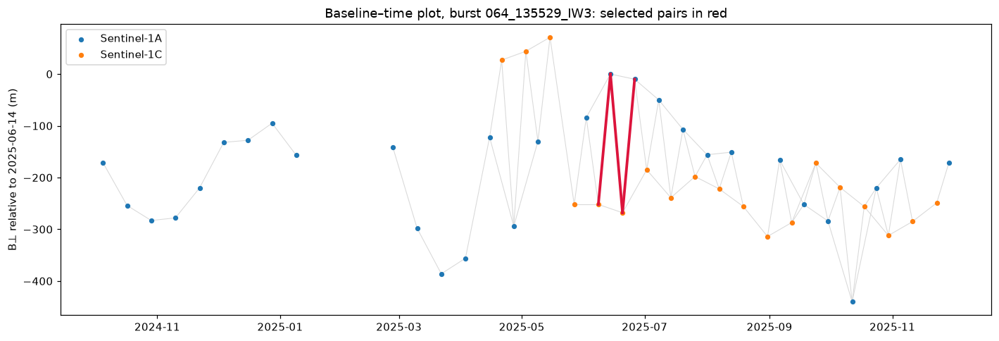

In [ ]:
# Select all acquisitions within the specified date range
sel = stack[(stack.time >= "2024-10-01") & (stack.time <= "2025-11-30")]

# Set up the plot for baseline vs time
fig, ax = plt.subplots(figsize=(13, 4.5))

# Plot all candidate pairs (within the date range) as gray line segments indicating baseline separation between acquisitions
for _, r in cand[(pd.to_datetime(cand.reference) >= "2024-10-01") & (pd.to_datetime(cand.secondary) <= "2025-11-30")].iterrows():
    # Lookup the perpendicular baselines for both acquisitions in the pair
    a, b = stack.set_index(stack.time.dt.date).loc[[r.reference, r.secondary], "bperp"]
    # Draw a faint line connecting the two acquisitions in time vs. baseline
    ax.plot([r.reference, r.secondary], [a, b], color="0.85", lw=0.7, zorder=1)

# For each Sentinel-1 platform/variant, plot the acquisition times and corresponding perpendicular baselines as colored points
for p, c in [("S1A", "tab:blue"), ("S1B", "tab:purple"), ("S1C", "tab:orange"), ("S1D", "tab:green")]:
    s = sel[sel.platform == p]  # acquisitions of this platform
    if s.empty:  # skip platforms without acquisitions in the window
        continue
    # Scatter plot the data points for this platform
    ax.scatter(s.time, s.bperp, s=14, color=c, label=f"Sentinel-1{p[-1]}", zorder=2)

# Highlight the user-selected pairs (in PAIRS variable) with thick red line segments
for a, b in PAIRS:
    # For each pair, get the perpendicular baselines for both acquisitions
    pa, pb = (stack.set_index(stack.time.dt.date).loc[pd.Timestamp(d).date(), "bperp"] for d in (a, b))
    # Draw a bold red line connecting the two times/baselines
    ax.plot([pd.Timestamp(a), pd.Timestamp(b)], [pa, pb], color="crimson", lw=2.5, zorder=3)

# Label the axes and add a legend and title
ax.set(
    ylabel=f"B⊥ relative to {REF} (m)", 
    title=f"Baseline-time plot, burst {BURSTS[0]}: selected pairs in red"
)
ax.legend(loc="upper left")  # legend
plt.tight_layout()  # arrange
plt.show()  # draw

Burst 064_135529_IW3 has 416 acquisitions from November 2014 to October 2026, giving 575 pairs 6-12 days apart, 253 of them in June-October. The median |B⊥| of all candidate pairs is only 51 m: Sentinel-1 is flown in a narrow orbital tube, which suits DInSAR but gives most pairs a height of ambiguity of several hundred metres.

The three June 2025 pairs rank third to fifth among the dry-season candidates, with |B⊥| of 252-268 m. The two pairs ranked above them (September-October 2022) are 12-day pairs. The June 2025 pairs are 6-day pairs (Sentinel-1A and 1C alternating), so they decorrelate less, and they form a chain of four dates that Step 13 uses for averaging. In the baseline-time plot they are the red segments jumping between about 0 and −270 m.


## Precise orbits and baselines

The SLC metadata carries the orbit the processor had when the data were processed, which,
depending on when that was, can be anything from a predicted orbit to one nearly as good as the
final product. The **precise orbit (POEORB)**, computed about 20 days later from GNSS tracking, is
good to about 5 cm. `sar.download_orbit` fetches it from the open AWS `s1-orbits` bucket (it
needs only the mission and the acquisition time, which ASF's search metadata provides) and
`sar.crop_orbit` keeps the minutes around the acquisition. The baseline matters directly: heights
scale with 1/B⊥, so a relative baseline error δB⊥/B⊥ becomes the same relative error in every
height (over 3,450 m of relief, 1 % is 35 m), and an error in the baseline's direction tilts the
DEM. `insar.perpendicular_baseline` places each satellite at its zero-Doppler time for the AOI
centre and splits the vector between them into the components along and across the line of sight.


In [ ]:
# Search for all Sentinel-1 burst-mode SAR acquisitions that match the area of interest, burst IDs, polarization,
# and date range. The search returns product metadata for all relevant bursts.
res_all = asf_cached(
    "asf_bursts.json",  # cached file name
    platform=asf.PLATFORM.SENTINEL1, 
    processingLevel="BURST", 
    fullBurstID=BURSTS, 
    polarization=POL,
    start=DATES[0], 
    end=str(pd.Timestamp(DATES[-1]) + pd.Timedelta(days=1))
)

# Build a DataFrame ('acq') summarizing acquisition metadata for each product:
# Including date, burst ID, platform (A/B/C/D), acquisition timestamp, and file size (MB).
acq = pd.DataFrame([
    {
        "date": p.properties["startTime"][:10],                              # Date in YYYY-MM-DD
        "burst": p.properties["burst"]["fullBurstID"],                       # Burst ID
        "platform": p.properties["platform"],                                # Sentinel-1 platform
        "start": pd.Timestamp(p.properties["startTime"]).tz_convert(None),   # Start time (UTC, naive datetime)
        "MB": float(p.properties["bytes"]) / 1e6                             # File size in megabytes
    }
    for p in res_all
]).sort_values(["date", "burst"])

# For each date, download the corresponding precise orbit file using the platform and earliest product's time,
# and store the local path in the 'eof' dictionary.
eof = {
    d: sar.download_orbit(g.platform.iloc[0], g.start.min(), CACHE / "orbits")
    for d, g in acq.groupby("date")
}

# Crop each orbit file to the time window covering all bursts for that date, with a 6-second margin,
# and store these in the 'orbits' dictionary.
orbits = {
    d: sar.crop_orbit(eof[d], g.start.min(), g.start.max() + pd.Timedelta(seconds=6))
    for d, g in acq.groupby("date")
}

# Compute area of interest center coordinates and a reference height (AOI: [xmin, ymin, xmax, ymax]).
lon_c = (AOI[0] + AOI[2]) / 2
lat_c = (AOI[1] + AOI[3]) / 2  # latitude of the AOI centre
h_c = 800.0  # Reference height in meters

# Retrieve ASF baseline (B⊥) for each date, indexed by acquisition date.
asf_bperp = stack.set_index(stack.time.dt.date)["bperp"]

# For each user-selected pair of acquisition dates (a, b):
#   - Compute precise perpendicular and parallel baselines and related geometry parameters;
#   - Calculate height of ambiguity (h_a);
#   - Assemble a summary row for the output table, including B⊥ from precise orbits and ASF,
#     parallel baseline, slant range, incidence angle, h_a, and number of fringes over 3450 m height difference.
base, rows = {}, []
for a, b in PAIRS:  # each selected pair
    # Compute baseline geometry for this pair.
    g = {k: float(v[0]) 
         for k, v in insar.perpendicular_baseline(
            orbits[a], orbits[b], [lat_c], [lon_c], h_c
         ).items()}
    # Calculate height of ambiguity for this pair.
    g["h_a"] = float(insar.height_of_ambiguity(0.05546576, g["slant_range"], g["incidence"], g["bperp"]))
    base[a, b] = g  # keep the geometry of the pair
    # Add a summary row for this pair.
    rows.append({
        "pair": f"{a} / {b}",
        "B⊥ precise orbits (m)": round(g["bperp"], 1),
        "B⊥ ASF (m)": round(asf_bperp[pd.Timestamp(b).date()] - asf_bperp[pd.Timestamp(a).date()], 1),
        "B∥ (m)": round(g["bparallel"], 1),
        "slant range (km)": round(g["slant_range"] / 1e3, 1),
        "incidence (°)": round(g["incidence"], 1),
        "h_a (m per fringe)": round(g["h_a"], 1),
        "fringes over 3,450 m": round(3450 / abs(g["h_a"])),
    })

# Print which precise orbit files were acquired/used.
print("orbit files:", *[p.name for p in eof.values()], sep="\n  ")

# Create and display a DataFrame summarizing the geometry for each selected pair.
pair_table = pd.DataFrame(rows).set_index("pair")
pair_table  # show the table

orbit files:
  S1C_OPER_AUX_POEORB_OPOD_20250628T070952_V20250607T225942_20250609T005942.EOF
  S1A_OPER_AUX_POEORB_OPOD_20250704T070625_V20250613T225942_20250615T005942.EOF
  S1C_OPER_AUX_POEORB_OPOD_20250710T070950_V20250619T225942_20250621T005942.EOF
  S1A_OPER_AUX_POEORB_OPOD_20250716T070654_V20250625T225942_20250627T005942.EOF


,B⊥ precise orbits (m),B⊥ ASF (m),B∥ (m),slant range (km),incidence (°),h_a (m per fringe),"fringes over 3,450 m"
pair,,,,,,,
2025-06-08 / 2025-06-14,254.9,252.0,195.9,926.9,43.7,69.7,50
2025-06-14 / 2025-06-20,-272.7,-268.0,-205.2,926.7,43.7,-65.1,53
2025-06-20 / 2025-06-26,264.5,258.0,187.3,926.9,43.7,67.2,51


The precise-orbit baselines agree with ASF's baseline tool to within 1-3 % (255 vs 252 m, −273 vs −268 m, 265 vs 258 m). ASF evaluates the baseline at its own reference point and with the metadata orbits, so a small difference is expected; the sign convention is the same (positive when the secondary is on the far-from-Earth side). At the AOI centre the slant range is 927 km and the incidence angle 43.7°, so one fringe corresponds to 65-70 m of height, and the 3,450 m of relief between Badwater Basin and Telescope Peak spans 50-53 fringes.

## TOPS Split, downloading the bursts

Sentinel-1 IW acquires three sub-swaths (IW1-IW3) in **bursts** of about 3 s (20 km along track),
steering the antenna forward during each burst (Terrain Observation by Progressive Scans, TOPS).
ASF's burst extractor serves single bursts, so "TOPS Split" here is: pick the bursts covering
the AOI (two consecutive bursts of IW3, which overlap by about 2 km and are needed for ESD),
download them with `rs.access.asf_download` (Earthdata login from `~/.netrc`), and keep only the
range samples covering the AOI (`sar.burst_window`). Each burst comes with its annotation (timing,
Doppler, orbit, geolocation grid), which `sar.read_slc_annotation` parses; `sar.apply_orbit_file`
then swaps in the precise orbit.


In [ ]:
# 1. Set up the cache directory for storing processed SLC (Single Look Complex) bursts.
SLC = CACHE / "slc"
SLC.mkdir(exist_ok=True)  # Ensure the directory exists for storing SLC data.

# 2. Define a function to fetch and preprocess radar "bursts" for a specific acquisition date.
def fetch_bursts(date):
    # If all required burst files for this date already exist in the cache, do nothing.
    if all((SLC / f"{date}_{b}.npy").exists() for b in BURSTS):
        return
    
    # a. Search ASF for the bursts of this date (only reached when they have to be downloaded).
    res = asf.search(platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST", fullBurstID=BURSTS,
                     polarization=POL, start=date, end=str(pd.Timestamp(date) + pd.Timedelta(days=1)))
    raw = CACHE / "raw"  # folder for the raw ASF downloads
    raw.mkdir(exist_ok=True)  # Directory for temporary/raw downloads.
    
    # b. Download the raw burst data (zip/tif/xml) from ASF.
    rs.access.asf_download(res, raw)
    
    # c. For each downloaded burst:
    for p in res:
        bid = p.properties["burst"]["fullBurstID"]   # Unique burst identifier (for filename)
        name = p.properties["fileID"]                # File name base
        
        # Find the matching files: image (tif) and its annotation (xml).
        tif = next(raw.glob(f"{name}*.tif*"))
        xml = next(raw.glob(f"{name}*.xml"))  # the matching annotation XML
        
        # Parse the annotation for this burst.
        a = sar.read_slc_annotation(xml, swath=bid[-3:], polarisation=POL)
        i = p.properties["burst"]["burstIndex"]      # Index of the burst in the annotation
        c = sar.burst_window(a, i, AOI, margin=300)  # Compute the column window (range samples) to keep
        
        # Read/crop the SLC burst for just the columns covering the AOI.
        z = sar.read_slc_burst(tif, a, i, cols=c)
        
        # Save the complex SLC burst: stack real/imag as int16, lossless encoding.
        np.save(SLC / f"{date}_{bid}.npy", np.stack([z.real, z.imag]).astype("int16"))
        
        # Move/copy annotation XML to cache, rename as needed.
        xml.replace(SLC / f"{date}_{bid}.xml")
        
        # Save burst metadata into a compact JSON file.
        pd.Series({
            "burst_index": i,
            "col0": c[0],
            "col1": c[1],
            "file": name,
            "platform": p.properties["platform"]
        }).to_json(SLC / f"{date}_{bid}.json")
        
        # Delete the original tiff file to save space.
        tif.unlink()

# 3. Loop through all dates, fetching and caching the necessary bursts for each.
t0 = time.time()
for date in DATES:  # every date
    fetch_bursts(date)  # download and crop its bursts (skipped when cached)
# number of bursts, download size and run time
print(f"{len(acq)} bursts ({acq.MB.sum() / 1e3:.1f} GB to download) ready in {time.time() - t0:.0f} s")

# 4. For each burst in each date, read the cached metadata, annotation, and SLC array into dictionaries.
ann, slc, meta = {}, {}, {}
for date in DATES:  # every date ...
    for b in BURSTS:  # ... and every burst
        # Load burst metadata from JSON as a pandas Series.
        meta[date, b] = pd.read_json(SLC / f"{date}_{b}.json", typ="series")
        # Read the burst annotation XML.
        ann[date, b] = sar.read_slc_annotation(SLC / f"{date}_{b}.xml", swath=b[-3:], polarisation=POL)
        # Load the SLC burst array and reconstruct the complex signal.
        ri = np.load(SLC / f"{date}_{b}.npy")
        # rebuild the complex SLC from the stored real and imaginary parts
        slc[date, b] = (ri[0] + 1j * ri[1]).astype("complex64")

# 5. Apply the precise-orbit correction to the annotation data for further geolocation accuracy.
pann = {k: sar.apply_orbit_file(a, orbits[k[0]]) for k, a in ann.items()}

# 6. Extract key info from the reference burst after orbit file application.
a0 = pann[REF, BURSTS[0]]
lam = a0["wavelength"]  # Wavelength in meters

# 7. Prepare indexing and cropping information used for analysis, for each burst.
idx = {k: int(m.burst_index) for k, m in meta.items()}
cols = {k: (int(m.col0), int(m.col1)) for k, m in meta.items()}  # range-sample window kept for each burst

# 8. Print concise metadata about the reference burst acquisition and array layout.
print(
    f"{a0['mission']} {a0['swath']} {a0['polarisation']} {a0['pass']}, heading {a0['heading']:.1f}°, "
    f"λ = {a0['wavelength'] * 100:.3f} cm; burst {a0['lines_per_burst']} lines x {a0['samples_per_burst']} samples, "
    f"pixel {a0['range_pixel_spacing']:.2f} m (slant range) x {a0['azimuth_pixel_spacing']:.2f} m (azimuth)"
)

# 9. Summarize each burst with a DataFrame, one row per date/burst, with platform info, sample window, array shape, and valid azimuth lines.
pd.DataFrame([
    {
        "date": d,
        "burst": b,
        "platform": meta[d, b].platform,
        "index in slice": idx[d, b],
        "samples kept": f"{cols[d, b][0]}-{cols[d, b][1]}",
        "array": f"{slc[d, b].shape[0]} x {slc[d, b].shape[1]}",
        "valid lines": f"{ann[d, b]['bursts'][idx[d, b]]['first_valid_line']}-{ann[d, b]['bursts'][idx[d, b]]['last_valid_line']}"
    }
    for d in DATES for b in BURSTS
])

8 bursts (1.2 GB to download) ready in 0 s


S1A IW3 VV Ascending, heading 346.9°, λ = 5.547 cm; burst 1513 lines x 24584 samples, pixel 2.33 m (slant range) x 13.91 m (azimuth)


,date,burst,platform,index in slice,samples kept,array,valid lines
0,2025-06-08,064_135529_IW3,SENTINEL-1C,3,4395–17149,1514 x 12754,28–1487
1,2025-06-08,064_135530_IW3,SENTINEL-1C,4,4395–17149,1514 x 12754,29–1486
2,2025-06-14,064_135529_IW3,SENTINEL-1A,2,4192–16943,1513 x 12751,28–1486
3,2025-06-14,064_135530_IW3,SENTINEL-1A,3,4192–16943,1513 x 12751,29–1487
4,2025-06-20,064_135529_IW3,SENTINEL-1C,3,4399–17153,1514 x 12754,28–1486
5,2025-06-20,064_135530_IW3,SENTINEL-1C,4,4399–17153,1514 x 12754,30–1487
6,2025-06-26,064_135529_IW3,SENTINEL-1A,2,4201–16952,1512 x 12751,28–1485
7,2025-06-26,064_135530_IW3,SENTINEL-1A,3,4201–16952,1512 x 12751,28–1485


In [ ]:
# This code block evaluates the effect of applying precise orbit data (from external "precise orbit files") vs using metadata-provided orbits, for accurate geolocation and baseline calculation in InSAR.
rows = []

# For each date, compute the positional difference at the burst center between:
# 1. The orbit interpolated from the metadata (inside the product) and
# 2. The orbit interpolated using externally supplied precise orbits.
for d in DATES:
    # Extract annotation for the first burst on date d
    a = ann[d, BURSTS[0]]
    # Find the azimuth (along-track) time for the reference point in this burst
    t = a["bursts"][idx[d, BURSTS[0]]]["azimuth_time"]
    # Interpolate satellite position at time t using the two orbits
    pa, _ = sar.interpolate_orbit(a["orbit"], [t])      # From product metadata
    pp, _ = sar.interpolate_orbit(orbits[d], [t])       # From precise orbit file
    # Compute and store the spatial difference (in meters)
    rows.append({
        "date": d,
        "mission": a["mission"],
        "metadata vs precise position (m)": round(float(np.linalg.norm(pa - pp)), 3)
    })

# For each image pair (for interferometry), compare the perpendicular baselines (B⊥) computed two ways:
#   - Using orbits from metadata only
#   - Using precise orbits (presumably from 'base', which was separately computed)
# Also estimate a height scaling error over a reference height difference (here 3,450 m),
# which quantifies the relative error in height measurement introduced by a difference in B⊥.
for a, b in PAIRS:
    # Calculate perpendicular baseline using metadata orbits
    bm = insar.perpendicular_baseline(
        ann[a, BURSTS[0]]["orbit"], ann[b, BURSTS[0]]["orbit"], [lat_c], [lon_c], h_c
    )["bperp"][0]  # from metadata orbits

    # bm: B⊥ from metadata, base[a, b]["bperp"]: B⊥ from precise orbits
    rows.append({
        "date": f"pair {a} / {b}",
        "B⊥ metadata orbits (m)": round(float(bm), 2),
        "B⊥ precise orbits (m)": round(base[a, b]["bperp"], 2),
        # Height error estimation: difference in B⊥ scales the measured height
        "height scale error over 3,450 m (m)": round(3450 * abs(bm - base[a, b]["bperp"]) / abs(base[a, b]["bperp"]), 1)
    })

# Summarize findings in a DataFrame for display:
#   - For single scenes: mission and orbit difference (in meters)
#   - For pairs: both B⊥ values and their impact on height measurements
pd.DataFrame(rows).set_index("date").fillna("")

,mission,metadata vs precise position (m),B⊥ metadata orbits (m),B⊥ precise orbits (m),"height scale error over 3,450 m (m)"
date,,,,,
2025-06-08,S1C,0.023,,,
2025-06-14,S1A,0.012,,,
2025-06-20,S1C,0.042,,,
2025-06-26,S1A,0.013,,,
pair 2025-06-08 / 2025-06-14,,,254.9,254.9,0.0
pair 2025-06-14 / 2025-06-20,,,-272.74,-272.74,0.0
pair 2025-06-20 / 2025-06-26,,,264.46,264.46,0.0


The first run downloads the eight bursts (1.2 GB) in about 4 minutes; later runs read the cache. In the burst-extractor files a burst has 1,512-1,514 lines and 24,584-24,990 range samples, of which the AOI needs about 12,750 (columns 4,192-17,153, depending on the date). The first 28-30 and the last 26-28 lines of every burst are invalid (zero-filled).

**What Apply-Orbit-File changed here: almost nothing.** The orbit in these 2025 products already agrees with POEORB to 1-4 cm, and the baselines from the two orbits agree to the centimetre. That is not guaranteed, though. Products processed in near real time carry a less accurate orbit, and an error δB⊥ scales every height by δB⊥/B⊥: 10 cm on a 270 m baseline is 0.04 %, or about 1.3 m over 3,450 m of relief. Applying the precise orbit is cheap insurance.


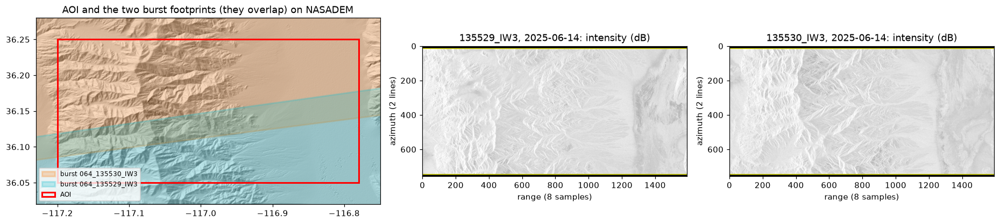

In [ ]:
# This section visualizes the locations of radar bursts and the Area of Interest (AOI), and shows how a burst looks in radar geometry.

# First, try to load a (NASADEM) digital elevation model (DEM) that includes geoid heights from disk.
dem_geoid = rioxarray.open_rasterio(CACHE / "nasadem_geoid.tif").squeeze(drop=True) if (CACHE / "nasadem_geoid.tif").exists() else None

# If the DEM is not found locally, download it (and Copernicus DEM as well) from the Microsoft Planetary Computer via STAC API.
if dem_geoid is None:
    import planetary_computer as pc  # Planetary Computer URL signing
    import pystac_client  # STAC search client
    from rioxarray.merge import merge_arrays  # mosaic several rasters

    # Connect to the planetary computer catalog and define a slightly padded bounding box around the AOI.
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)
    box = (AOI[0] - 0.03, AOI[1] - 0.03, AOI[2] + 0.03, AOI[3] + 0.03)  # the AOI plus a 0.03 degree margin

    # For both NASADEM ("nasadem") and Copernicus DEM ("cop-dem-glo-30"), download, mosaic, and save DEM tiles covering the area.
    for coll, asset, name in [("nasadem", "elevation", "nasadem"), ("cop-dem-glo-30", "data", "copdem30")]:
        # Load and clip tiles to the bounding box, mosaic them with merge_arrays
        tiles = [rioxarray.open_rasterio(i.assets[asset].href).squeeze("band", drop=True).rio.clip_box(*box)
                 for i in cat.search(collections=[coll], bbox=box).items()]
        da = merge_arrays(tiles).astype("float32")  # mosaic the tiles
        # Mask nodata values before saving
        da.where(da != da.rio.nodata).rio.to_raster(CACHE / f"{name}_geoid.tif")
    # Reload the just-downloaded NASADEM as 'dem_geoid'
    dem_geoid = rioxarray.open_rasterio(CACHE / "nasadem_geoid.tif").squeeze(drop=True)

from shapely.geometry import shape  # GeoJSON geometry -> shapely polygon

# Set up a figure with three panels (subplots): one for the DEM and AOI, two for radar bursts.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ls = LightSource(azdeg=315, altdeg=40)  # light source for the hillshade (from the north-west, 40 degrees high)
# Determine plotting extent from DEM coordinates
ext = [float(dem_geoid.x.min()), float(dem_geoid.x.max()), float(dem_geoid.y.min()), float(dem_geoid.y.max())]

# Left-most plot: shaded relief (hillshade) of DEM
axes[0].imshow(ls.hillshade(np.nan_to_num(dem_geoid.values), vert_exag=1, dx=25, dy=31), cmap="gray", extent=ext)

# Overlay the two SLC burst footprints associated with the reference date (REF)
for p_, c in zip([p for p in res_all if p.properties["startTime"][:10] == REF], ["tab:orange", "tab:cyan"]):
    x_, y_ = shape(p_.geometry).exterior.xy  # outline coordinates of the burst footprint
    # fill the footprint in its colour
    axes[0].fill(x_, y_, color=c, alpha=0.25, lw=2, ec=c, label=f"burst {p_.properties['burst']['fullBurstID']}")

# Draw the AOI rectangle on the DEM, in red
axes[0].add_patch(plt.Rectangle(AOI[:2], AOI[2] - AOI[0], AOI[3] - AOI[1], fill=False, ec="red", lw=2, label="AOI"))
axes[0].set(  # zoom to the AOI with a margin, and set the title
    xlim=(AOI[0] - 0.03, AOI[2] + 0.03),
    ylim=(AOI[1] - 0.03, AOI[3] + 0.03),
    title="AOI and the two burst footprints (they overlap) on NASADEM"
)
axes[0].legend(loc="lower left", fontsize=8)  # legend

# Calculate ground range pixel spacing for radiometric geocoding/display
ground_rg = a0["range_pixel_spacing"] / np.sin(np.radians(a0["incidence_mid"]))

# For each radar burst, display a radiometric (amplitude, in dB) image.
for ax, b in zip(axes[1:], BURSTS):
    # Multilook the burst for better SNR and convert to log-scale (dB)
    amp = 10 * np.log10(sar.multilook(np.abs(slc[REF, b]) ** 2, (2, 8)) + 1e-3)
    ax.imshow(  # the burst intensity in dB with a 2-98 % stretch
        amp,
        cmap="gray",
        vmin=np.nanpercentile(amp, 2),
        vmax=np.nanpercentile(amp, 98),
        aspect=2 * a0["azimuth_pixel_spacing"] / (8 * ground_rg))
    # Mark invalid (zero-filled) lines at top/bottom of burst, using yellow lines
    info = ann[REF, b]["bursts"][idx[REF, b]]
    for ln in (info["first_valid_line"], info["last_valid_line"]):  # first and last valid line of the burst
        ax.axhline(ln / 2, color="yellow", lw=0.8)  # draw them (divided by 2: the image has 2 azimuth looks)
    ax.set(  # title and axis labels
        title=f"{b[4:]}, {REF}: intensity (dB)",
        xlabel="range (8 samples)",
        ylabel="azimuth (2 lines)"
    )

plt.tight_layout()  # arrange
plt.show()  # draw

In radar geometry, azimuth runs down the image (the satellite flies roughly north on this
ascending pass) and slant range across it, increasing to the east; the bursts look east, so
west-facing slopes of the Panamint Range are compressed (foreshortened). The yellow lines mark the
valid lines: the first and last lines of each burst are zero-filled.

## Back-geocoding with TOPS deramping

**Back-geocoding** co-registers the secondary burst to the reference without image matching: every
DEM cell (NASADEM, converted from EGM96 geoid heights to WGS84 ellipsoidal heights, because orbits
and range-Doppler equations live on the ellipsoid) is located in both bursts with the range-Doppler
equations (`sar.geo2rdr`: zero-Doppler time and slant range on each precise orbit). That gives,
for every reference pixel, its fractional position in the secondary burst, plus the geometry the
interferogram needs later: the flat-Earth range difference and the phase-to-height factor.

Interpolating a TOPS burst at those positions needs one more step. Because the antenna sweeps
forward during the burst, the azimuth spectrum drifts by several kHz from the first line to the
last, far beyond the 486 Hz azimuth sampling rate; interpolating such a signal directly would
destroy it. `sar.resample_slc` therefore **deramps** the burst (multiplies by the conjugate of the
known Doppler ramp, `sar.tops_deramp_phase`), interpolates, then **reramps** at the new positions.


NASADEM: -143 to 3348 m above the EGM96 geoid; geoid undulation -30.0 m


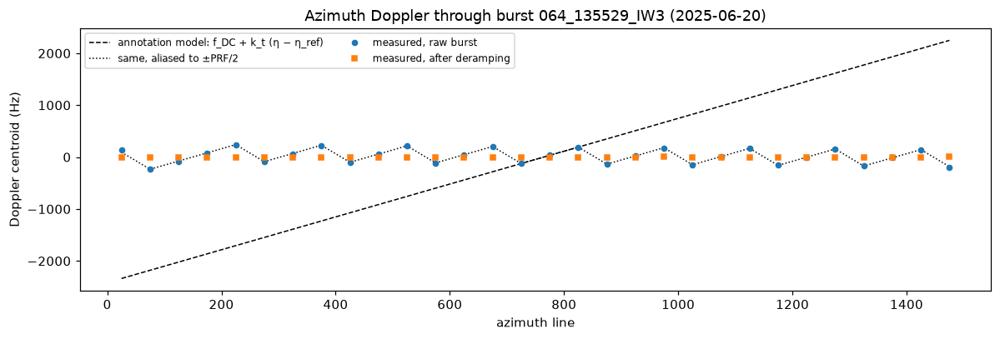

raw burst: model sweeps -2180 to 2248 Hz (PRF 486 Hz); after deramping: measured -0.6 ± 1.6 Hz


In [ ]:
# Convert the DEM (Digital Elevation Model) from geoid heights (EGM96) to ellipsoidal heights (WGS84 ellipsoid).
ell_file = CACHE / "nasadem_ellipsoid.tif"  # the same DEM above the WGS 84 ellipsoid, saved by an earlier run
if ell_file.exists():  # converted before: read it from the local drive
    dem_ell = rioxarray.open_rasterio(ell_file).squeeze(drop=True)
else:  # first run: add the EGM96 geoid undulation (PROJ reads the geoid grid online) and save it
    dem_ell = insar.geoid_to_ellipsoid(dem_geoid, "EGM96")
    dem_ell.rio.to_raster(ell_file)  # keep it for the next run
print(  # elevation range and mean geoid undulation
    f"NASADEM: {float(dem_geoid.min()):.0f} to {float(dem_geoid.max()):.0f} m above the EGM96 geoid; "
    f"geoid undulation {dem_ell.attrs['geoid_undulation_mean']:.1f} m"
)
# Here, geoid undulation denotes the average height difference between the reference geoid and ellipsoid.

# Select the first burst ('b') from the list of bursts, and set the date/index ('d') for the secondary acquisition (SEC).
b, d = BURSTS[0], SEC
info = ann[d, b]  # annotation of that burst and date
c0, c1 = cols[d, b]  # range-sample window of the burst

# Pick a window centered in range over 1000 samples, and extract the raw SLC data.
mid = slice((c1 - c0) // 2 - 500, (c1 - c0) // 2 + 500)
raw = slc[d, b][:, mid]  # the raw SLC of that window

# Create arrays for azimuth (lines) and range (samples) coordinates, used for Doppler calculation.
lines = np.arange(raw.shape[0], dtype=float)[:, None]
samples = np.arange(c0, c1, dtype=float)[mid][None, :]  # range-sample number of every column

# Apply deramping to the burst, removing the azimuth-dependent Doppler phase.
deramped = raw * np.exp(1j * sar.tops_deramp_phase(pann[d, b], idx[d, b], lines, samples))

# Measure the Doppler centroid (frequency shift) before and after deramping using small analysis blocks along azimuth.
cl, f_raw = sar.estimate_doppler_centroid(raw, info["azimuth_time_interval"], block=50)
# Doppler centroid of the deramped burst
_, f_der = sar.estimate_doppler_centroid(deramped, info["azimuth_time_interval"], block=50)

# Compute the modeled Doppler centroid as annotated in the product, for comparison.
f_model = sar.tops_doppler_centroid(pann[d, b], idx[d, b], cl, (c0 + c1) / 2)
prf = 1 / info["azimuth_time_interval"]  # PRF = Pulse Repetition Frequency, in Hz.

# Plot the measured and modeled Doppler centroids to visualize Doppler variation through the burst:
fig, ax = plt.subplots(figsize=(11, 3.8))
# the modelled Doppler centroid
ax.plot(cl, f_model, "k--", lw=1, label="annotation model: f_DC + k_t (η − η_ref)")
# the same, wrapped into the PRF interval as a measurement sees it
ax.plot(cl, (f_model + prf / 2) % prf - prf / 2, "k:", lw=1, label="same, aliased to ±PRF/2")
ax.plot(cl, f_raw, "o", ms=4, label="measured, raw burst")  # measured on the raw burst
# measured after deramping (should be near 0 Hz)
ax.plot(cl, f_der, "s", ms=4, label="measured, after deramping")
ax.set(  # labels and title
    xlabel="azimuth line",
    ylabel="Doppler centroid (Hz)",
    title=f"Azimuth Doppler through burst {b} ({d})"
)
ax.legend(fontsize=8, ncol=2)  # legend
plt.tight_layout()  # arrange
plt.show()  # draw

# Restrict statistics to the valid (non-zero-filled) lines in the burst.
bi = info["bursts"][idx[d, b]]
ok = (cl > bi["first_valid_line"]) & (cl < bi["last_valid_line"])  # lines inside the valid part of the burst

# Report the modeled sweep range and the deramped measured values within valid lines.
print(
    f"raw burst: model sweeps {f_model[ok].min():.0f} to {f_model[ok].max():.0f} Hz (PRF {prf:.0f} Hz); "
    f"after deramping: measured {np.median(f_der[ok]):.1f} ± {np.std(f_der[ok]):.1f} Hz"
)
 

In [ ]:
# The coregister function performs back-geocoding and resampling for a given burst from a secondary acquisition (sec_date)
# so it matches the geometry of a reference acquisition (ref_date). Optionally, it can deramp the signal and can apply an
# extra line shift to correct for any remaining azimuth misregistration.
def coregister(ref_date, sec_date, burst, extra_line_shift=0.0, deramp=True):
    # Step 1: Perform back-geocoding, which computes the mapping between secondary and reference grids
    g = sar.back_geocode(
        pann[ref_date, burst], pann[sec_date, burst],
        idx[ref_date, burst], idx[sec_date, burst],
        dem_ell, cols=cols[ref_date, burst]
    )
    # Step 2: Resample the secondary burst SLC onto the reference burst grid using the mapping from back-geocoding.
    # If deramp=True, compensates for Doppler by deramping the signal.
    res = sar.resample_slc(
        slc[sec_date, burst],
        g["sec_line"] - extra_line_shift,
        g["sec_sample"],
        ann=pann[sec_date, burst] if deramp else None,
        burst=idx[sec_date, burst],
        col0=cols[sec_date, burst][0]
    )
    # Return both the geometric mapping and the resampled SLC
    return g, res

# Coregistration is performed for all bursts between the reference and secondary dates.
t0 = time.time()
geom, sec_res = {}, {}  # geometry and resampled SLC per burst
for b in BURSTS:  # every burst
    # For each burst, store the geometric mapping and result of resampling
    geom[b], sec_res[b] = coregister(REF, SEC, b)
print(f"back-geocoding + resampling of {len(BURSTS)} bursts: {time.time() - t0:.0f} s")  # run time

# For the first burst, calculate and report the offset in azimuth lines and range samples between
# the resampled secondary position and the reference position.
g = geom[BURSTS[0]]
lines = np.arange(g["sec_line"].shape[0])[:, None]  # azimuth line indices
samples = np.arange(*cols[REF, BURSTS[0]])[None, :] # range sample indices
d_line = g["sec_line"] - lines                      # azimuth offset between secondary and reference
d_samp = g["sec_sample"] - samples                  # range offset between secondary and reference

print(  # offset range in lines and samples
    f"secondary position minus reference: azimuth {np.nanmin(d_line):.2f} to {np.nanmax(d_line):.2f} lines, "
    f"range {np.nanmin(d_samp):.2f} to {np.nanmax(d_samp):.2f} samples"
)

back-geocoding + resampling of 2 bursts: 84 s
secondary position minus reference: azimuth -0.38 to -0.18 lines, range 194.26 to 198.32 samples


In [ ]:
# Function to compute multilooked coherence between two SLC images, with optional phase correction
def ml_coherence(m, s, phase=0.0, looks=(4, 16)):
    """
    Estimate the multilooked coherence between two complex SAR images.

    Parameters:
    m, s: complex arrays (e.g., master and slave SLC bursts)
    phase: phase compensation to be removed (e.g., DEM-predicted phase)
    looks: tuple (azimuth_looks, range_looks) specifying the multilook window

    Returns:
    Multilooked coherence map as an array.
    """
    # Form the complex cross-correlation with possible phase correction
    i = m * np.conj(s) * np.exp(-1j * phase)
    # Numerator: multilooked magnitude of cross-correlation (coherent sum)
    num = np.abs(insar.multilook_complex(i, looks))
    # Denominator: square root of the product of multilooked powers
    den = np.sqrt(
        sar.multilook(np.abs(m) ** 2, looks) * 
        sar.multilook(np.abs(s) ** 2, looks)
    )
    # Coherence estimate, avoiding division by zero
    return num / np.maximum(den, 1e-30)

# Select the first burst for demonstration
b = BURSTS[0]

# Coregister secondary burst WITHOUT deramping for comparison
_, sec_noderamp = coregister(REF, SEC, b, deramp=False)

# Compute the DEM-predicted phase for flat-earth and topographic contributions
flat = insar.flat_earth_phase(geom[b]["flat_delta_range"], lam)
topo = insar.flat_earth_phase(geom[b]["delta_range"], lam)  # For this check only

# Generate a valid data mask (where both SLCs are nonzero after coregistration)
valid = (slc[REF, b] != 0) & (sec_res[b] != 0)

# Compute coherence for two cases: (1) no deramping, (2) proper deramp-interpolate-reramp
checks = {
    "no deramping (plain interpolation)": ml_coherence(slc[REF, b], sec_noderamp, topo),
    "deramp - interpolate - reramp": ml_coherence(slc[REF, b], sec_res[b], topo)
}

# Build mask for multilooked pixels that have valid data (almost everywhere, >99% confidence)
v = sar.multilook(valid.astype(float), (4, 16)) > 0.99

# Create a pandas Series containing the median coherence for each coregistration method,
# after removing the DEM phase, with multilooks over 4x16 windows
pd.Series(
    {k: float(np.median(c[v])) for k, c in checks.items()},
    name="median coherence (DEM phase removed, 4 x 16 looks)"
).to_frame()

,"median coherence (DEM phase removed, 4 x 16 looks)"
no deramping (plain interpolation),0.741666
deramp - interpolate - reramp,0.832446


The deramping check shows the TOPS Doppler sweep clearly. The annotation model says the azimuth Doppler centroid runs from −2,180 Hz at the start of the burst to +2,248 Hz at its end, nine times the 486 Hz sampling rate, so the measured centroid of the raw burst wraps around repeatedly (blue dots following the aliased model). After deramping, the measured centroid is −0.6 ± 1.6 Hz throughout: the burst is at baseband and can be interpolated.

Back-geocoding of the two bursts takes about 80 s. The secondary (20 June) sits 194-198 range samples further out and 0.18-0.38 lines earlier than the reference (14 June); these offsets vary smoothly across the window, as expected from the orbit geometry and terrain. With deramping, the median coherence after removing the DEM-predicted phase is 0.83; plain interpolation without deramping gives 0.74. The loss is moderate here only because the azimuth offset is a third of a line; with larger offsets, plain interpolation degrades far more.

## Enhanced Spectral Diversity

Back-geocoding with precise orbits is accurate to a few hundredths of a pixel. For TOPS that is
not enough: in the burst **overlap** the same ground is seen twice, at the end of burst *n* looking
forward and at the start of burst *n + 1* looking backward, with Doppler centroids about 5 kHz
apart. An azimuth misregistration δ (seconds) adds the phase −2π f_DC δ to each interferogram, so
the two overlap interferograms disagree by 2π Δf_DC δ: 0.01 pixel already gives a phase jump of
about 30° at the burst boundary. **ESD** turns this around and measures δ from the double
difference ``arg(ifg_n · conj(ifg_n+1))`` over coherent overlap pixels (`sar.esd_azimuth_shift`),
then resamples the secondary again with the correction. A second ESD pass checks the residual.


In [ ]:
# --- Explanation of the enhanced spectral diversity (ESD) two-pass correction ---

# 1. Extract the reference SLC data, burst indices, and annotation objects for all bursts
refs = [slc[REF, b] for b in BURSTS]             # List of reference SLC data for each burst
burst_ids = [idx[REF, b] for b in BURSTS]        # Corresponding burst indices for each burst
anns_ref = [pann[REF, b] for b in BURSTS]        # Annotation objects for each burst

# 2. First ESD estimation pass (using the initially coregistered secondary)
#    This computes the line (along-track) misregistration in the burst overlap using the reference and current secondary
esd = [
    sar.esd_azimuth_shift(
        refs,
        [sec_res[b] for b in BURSTS],        # Current secondary SLCs (after back-geocoding)
        anns_ref[0], burst_ids,
        col0=cols[REF, BURSTS[0]][0],
        anns=anns_ref
    )
]
# Extract the estimated misregistration in lines (may be fractional)
shift = esd[0]["shift_lines"]

# 3. Re-coregister the secondary SLCs using the ESD-estimated shift for all bursts
sec_esd = {
    b: coregister(REF, SEC, b, extra_line_shift=shift)[1]
    for b in BURSTS
}

# 4. Second ESD estimation (after shift correction)
#    Perform a second ESD pass to check the residual misregistration after correction
esd.append(
    sar.esd_azimuth_shift(
        refs, [sec_esd[b] for b in BURSTS],
        anns_ref[0], burst_ids,
        col0=cols[REF, BURSTS[0]][0],
        anns=anns_ref
    )
)

# 5. Get azimuth time sampling interval for metric conversion
dt_az = a0["azimuth_time_interval"]

# 6. Summarize the results in a DataFrame for both steps (before/after ESD)
#    - overlap phase, doppler difference, misregistration (pixels and mm), and number of coherent overlap pixels
pd.DataFrame({
    "overlap phase (deg)": [np.degrees(e["phase"][0]) for e in esd],
    "Doppler difference (Hz)": [e["doppler_difference"][0] for e in esd],
    "misregistration (pixels)": [e["shift_lines"] for e in esd],
    "misregistration (mm on the ground)": [e["shift_lines"] * a0["azimuth_pixel_spacing"] * 1e3 for e in esd],
    "coherent overlap pixels": [e["coherent_pixels"][0] for e in esd]
}, index=["after back-geocoding", "after ESD correction"]).round(4)

,overlap phase (deg),Doppler difference (Hz),misregistration (pixels),misregistration (mm on the ground),coherent overlap pixels
after back-geocoding,13.6271,4241.2424,-0.0043,-60.3901,1311307
after ESD correction,-0.1114,4241.2415,0.0000,0.4939,1311262


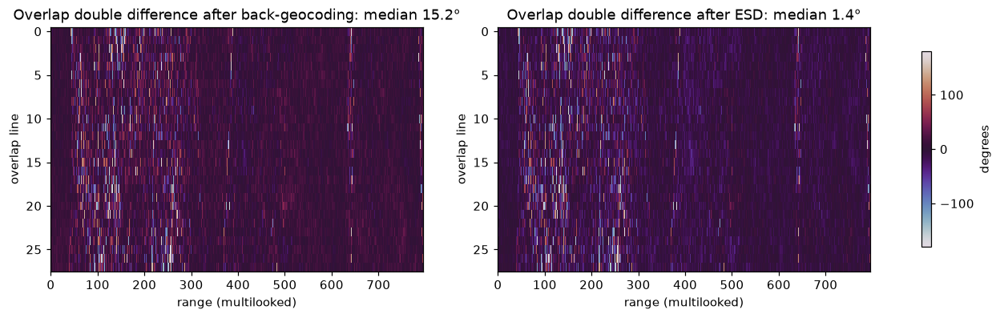

In [ ]:
# This block visualizes the phase discontinuity ("seam") at the overlap between two adjacent bursts,
# both before and after correction with ESD (Enhanced Spectral Diversity).
# 
# 1. It first computes, for the two bursts, the row indices (ra, rb) identifying exactly matching ground pixels in their respective arrays.
# 2. It then sets up a figure with two subplots: the left shows results "after back-geocoding" (before ESD), 
#    the right "after ESD" correction.
# 3. For both cases, it:
#    - Computes the interferometric phase for the overlap lines in each burst.
#    - Forms a "double difference": the reference burst multiplied by the conjugate of the secondary, then the product of both bursts' overlap multiplied and multilooked for noise reduction.
#    - Plots the phase (in degrees) of this double-differenced region, color-coded, with limits at -180° to 180°.
#    - Adds a title indicating the median double-difference phase over the overlap (as a diagnostic for misregistration).
# 4. It finally displays a shared colorbar and the figures.
# 5. The last line updates sec_res to be the ESD-corrected secondary SLCs for further processing.

# Code:
# Compute indices for the overlapping lines (the seam) for both bursts
ra, rb = sar.sentinel1._overlap_rows(
    sar.sentinel1._merge_burst_ann(anns_ref[0], anns_ref[1], *burst_ids),
    *burst_ids
)

# Set up 1 row, 2 column plot for before/after ESD correction
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))

# Iterate over the two cases: before (sec_res) and after (sec_esd) ESD, along with subplot and title
for ax, sec_set, title in [
    (axes[0], sec_res, "after back-geocoding"),
    (axes[1], sec_esd, "after ESD")
]:
    # Compute interferogram for overlap lines of first burst
    i0 = refs[0][ra] * np.conj(sec_set[BURSTS[0]][ra])
    # Compute interferogram for overlap lines of second burst
    i1 = refs[1][rb] * np.conj(sec_set[BURSTS[1]][rb])
    # Form the double-difference and apply multilooking (averaging over 4 x 16 window)
    dd = insar.multilook_complex(i0 * np.conj(i1), (4, 16))
    # Display the phase (in degrees) of the double-difference
    im = ax.imshow(
        np.degrees(np.angle(dd)),
        cmap="twilight",
        vmin=-180,
        vmax=180,
        aspect="auto",
        interpolation="none"
    )
    # Title shows which step (before/after ESD) and median phase for that region
    ax.set(
        title=(
            f"Overlap double difference {title}: "
            f"median {np.degrees(np.angle(np.nansum(dd))):.1f}°"
        ),
        xlabel="range (multilooked)",
        ylabel="overlap line"
    )

# Add a shared colorbar for phase
plt.colorbar(im, ax=axes, shrink=0.8, label="degrees")
plt.show()  # draw

# Update the working secondary SLC set for all further processing to the ESD-corrected version
sec_res = sec_esd

The overlap of the two bursts is 115 lines (about 1.6 km) long, with 1.3 million coherent pixels and a Doppler difference of 4,241 Hz between the forward- and backward-looking views. After back-geocoding with precise orbits, the double-difference phase is 13.6°, a misregistration of 0.0043 pixels: just 6 cm along track, yet enough for a visible phase step at the burst seam. One ESD correction brings the overlap phase to −0.1° and the misregistration to 0.5 mm. In the overlap maps, the median double-difference phase drops from 15° to about 1°, leaving only noise.

## Interferogram, flat-Earth phase and coherence

The interferogram is the reference times the complex conjugate of the resampled secondary. Its
phase is dominated by the **flat-Earth phase**: even with no terrain at all, the range difference
between the two orbits changes steadily across the swath (dozens of fringes). `back_geocode`
computed that range difference on the ellipsoid; `insar.flat_earth_phase` turns it into phase,
which is removed. The **topographic phase stays**: it is the signal. (DInSAR would subtract it
too, using the DEM; here the DEM was used only to place pixels.)


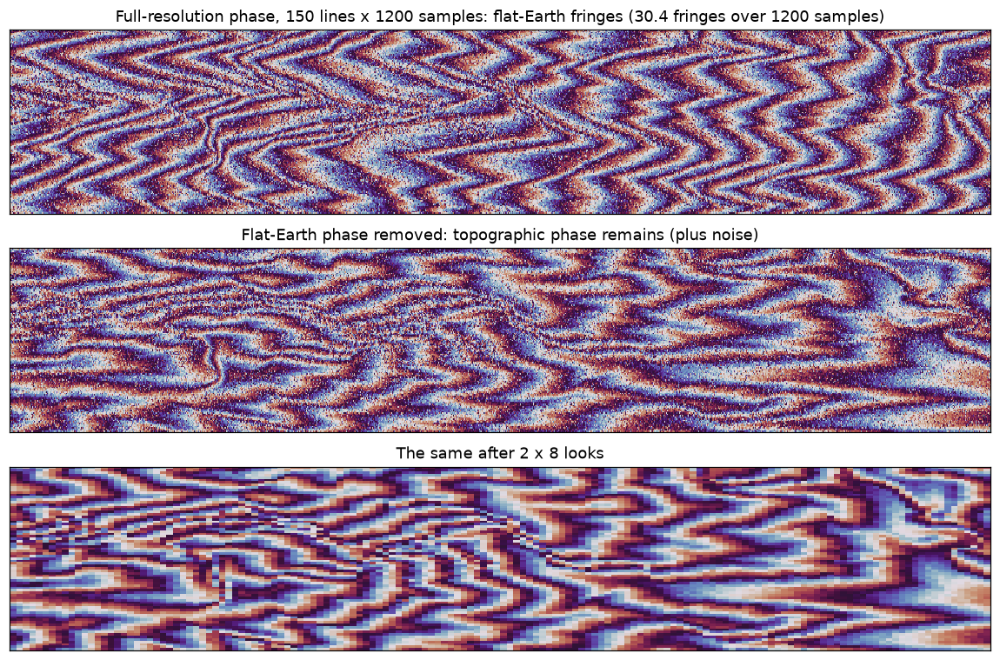

In [ ]:
# Dictionaries to hold outputs for each burst:
# - ifg_full: complex interferograms with flat-Earth phase removed
# - p_ref: intensity (power) from the reference SLC
# - p_sec: intensity (power) from the secondary SLC
# - flat_full: computed flat-Earth phase for each burst
ifg_full, p_ref, p_sec, flat_full = {}, {}, {}, {}
for b in BURSTS:  # every burst
    # Compute flat-Earth phase for each burst (accounts for geometric flat-Earth contribution)
    flat_full[b] = insar.flat_earth_phase(geom[b]["flat_delta_range"], lam)
    # Form interferogram: reference * conjugate(secondary), remove flat-Earth phase, replace NaNs with 0, enforce complex64 dtype
    ifg_full[b] = np.nan_to_num(
        slc[REF, b] * np.conj(sec_res[b]) * np.exp(-1j * flat_full[b])
    ).astype("complex64")  # Pixels with no data become 0
    # Compute power (intensity) images for reference and secondary SLCs for later use
    p_ref[b], p_sec[b] = np.abs(slc[REF, b]) ** 2, np.abs(sec_res[b]) ** 2

# Visualization region:
b = BURSTS[0]
r0 = 600  # Starting azimuth (line) index
c0 = (cols[REF, b][1] - cols[REF, b][0]) // 2  # Middle column index
win = (slice(r0, r0 + 150), slice(c0, c0 + 1200))  # 150 lines × 1200 columns window

# Compute "raw" (un-corrected) complex interferogram for this window
raw_ifg = slc[REF, b][win] * np.conj(sec_res[b][win])

# Set up 3 vertically stacked subplots for visualization
fig, axes = plt.subplots(3, 1, figsize=(15, 7))

# Panel 1: Phase of raw interferogram (shows flat-Earth fringes)
axes[0].imshow(np.angle(raw_ifg), cmap="twilight", aspect=1.5, interpolation="none")
axes[0].set_title(  # title of the first panel
    "Full-resolution phase, 150 lines x 1200 samples: flat-Earth fringes "
    f"({(flat_full[b][win][0, -1] - flat_full[b][win][0, 0]) / (2 * np.pi):.1f} fringes over 1200 samples)"
)

# Panel 2: Phase of interferogram after removing flat-Earth phase (topographic signal remaining)
axes[1].imshow(np.angle(ifg_full[b][win]), cmap="twilight", aspect=1.5, interpolation="none")
# title of the second panel
axes[1].set_title("Flat-Earth phase removed: topographic phase remains (plus noise)")

# Panel 3: Same as above, but after multilooking (spatial averaging) to reduce speckle
multi_ifg = insar.multilook_complex(ifg_full[b], LOOKS)
axes[2].imshow(  # the multilooked interferogram phase
    np.angle(multi_ifg)[
        r0 // LOOKS[0]:(r0 + 150) // LOOKS[0], 
        c0 // LOOKS[1]:(c0 + 1200) // LOOKS[1]
    ],
    cmap="twilight",
    aspect=1.5 * LOOKS[0] / LOOKS[1],
    interpolation="none"
)
axes[2].set_title(f"The same after {LOOKS[0]} x {LOOKS[1]} looks")  # title of the third panel

# Remove axis ticks for visual clarity
for ax in axes:
    ax.set_xticks([])  # no x ticks
    ax.set_yticks([])  # no y ticks

plt.tight_layout()  # arrange
plt.show()  # draw

## Deburst and multilook

**Deburst** (`sar.deburst`) joins the two bursts into one image: each burst keeps its valid lines,
and every overlap is cut at its middle, so each line comes from exactly one burst. Because the
whole AOI lies in sub-swath IW3, no **TOPS Merge** across sub-swaths is needed; an AOI spanning
IW2 and IW3 would be merged along range in the same way.

**Multilooking** averages 2 azimuth × 8 range pixels: 2 × 13.9 m along track and
8 × 2.33 m = 18.6 m in slant range, which is about 27 m on the ground at this incidence angle,
roughly square pixels. The interferogram is averaged as complex numbers (the phase of the sum).
Coherence is estimated from the multilooked products with a further 3 × 3 window (144 looks), and
the geometry layers are averaged the same way.


debursted: 2804 lines x 12751 samples -> multilooked 1402 x 1593 (27.8 m azimuth x 18.6 m slant range = 27.0 m ground range)
median coherence 0.68; above 0.4: 78% of pixels


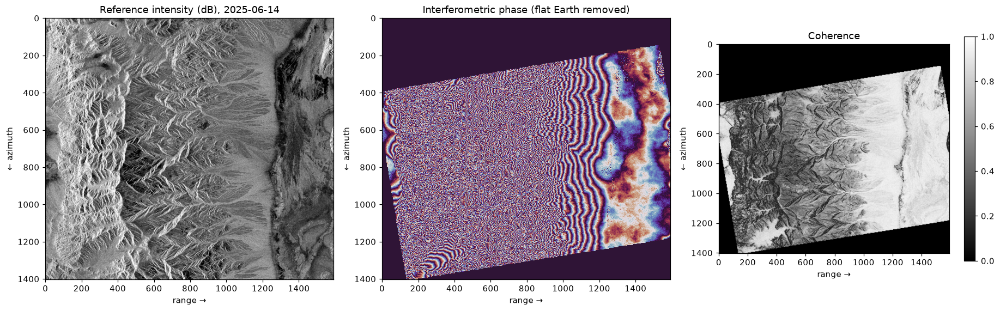

In [ ]:
# This section performs the debursting and multilooking steps
# in the InSAR workflow, then computes coherence and visualizes results.

def deburst_ml(layers, looks=LOOKS):
    """
    Deburst a {burst: array} layer, then multilook (complex or real).
    Takes a dictionary of arrays (one per burst), performs debursting
    to join into one image, then applies spatial averaging ("multilooking").
    Returns the multilooked image and times.
    """
    # Combine burst images into a continuous image
    img, t = sar.deburst([layers[b] for b in BURSTS], anns_ref[0], burst_ids, anns=anns_ref)
    # Apply multilooking (spatial averaging), handling both complex and real data
    if np.iscomplexobj(img):
        out = insar.multilook_complex(img, looks)  # complex data (interferogram): average the complex values
    else:
        out = sar.multilook(img.astype("float64"), looks)  # real data (intensity, geometry): average as floats
    return out, t  # return the image and its azimuth times

# Deburst the full-resolution interferogram to join all range bursts
ifg_db, times_full = sar.deburst([ifg_full[b] for b in BURSTS], anns_ref[0], burst_ids, anns=anns_ref)

# Deburst and multilook key layers: interferogram and reference/secondary intensities
ifg, _ = deburst_ml(ifg_full)
pm, _ = deburst_ml(p_ref)  # reference intensity, debursted and multilooked
ps, _ = deburst_ml(p_sec)  # secondary intensity, debursted and multilooked

# Deburst and multilook the geometry layers
G = {k: deburst_ml({b: geom[b][k] for b in BURSTS})[0] 
     for k in ("dem_height", "dheight_ddelta_range", "slant_range", "incidence")}

# Multilooking the time axis: average times within each 'looks' window
nt = (times_full.size // LOOKS[0]) * LOOKS[0]
# average the azimuth times of each group of looks
t_ml = times_full[:nt].astype("int64").reshape(-1, LOOKS[0]).mean(1).astype("datetime64[ns]")

# 3 x 3 boxcar mean used for the coherence estimate
def box(x, size=3):
    """
    Perform a 2D uniform (boxcar) filter of given size.
    Handles both complex and real arrays by filtering real and imaginary parts separately.
    """
    from scipy import ndimage  # uniform (boxcar) filter
    if np.iscomplexobj(x):  # complex input: filter real and imaginary parts separately
        # and recombine them
        return ndimage.uniform_filter(x.real, size) + 1j * ndimage.uniform_filter(x.imag, size)
    return ndimage.uniform_filter(x, size)  # real input: filter directly

# Identify valid pixels: nonzero interferogram amplitude, positive intensities, finite DEM
valid_ml = (
    (np.abs(ifg) > 0) & (pm > 0) & (ps > 0) & np.isfinite(G["dem_height"])
)

# Calculate local coherence (correlation between complex images), clipped to [0, 1]
coh = np.where(
    valid_ml,
    np.clip(
        np.abs(box(ifg)) / np.sqrt(box(pm) * box(ps) + 1e-30), 0, 1
    ),
    0,
)

# Compute spatial parameters and print summary stats
near_range = float(
    a0["slant_range_time"] * sar.SPEED_OF_LIGHT / 2
    + (cols[REF, BURSTS[0]][0] + (LOOKS[1] - 1) / 2) * a0["range_pixel_spacing"]
)
dr = LOOKS[1] * a0["range_pixel_spacing"]  # ground size of a multilooked pixel in range (m)
da = LOOKS[0] * a0["azimuth_pixel_spacing"]  # ground size of a multilooked pixel in azimuth (m)

print(  # image size and pixel size
    f"debursted: {ifg_db.shape[0]} lines x {ifg_db.shape[1]} samples"
    f" -> multilooked {ifg.shape[0]} x {ifg.shape[1]} "
    f"({da:.1f} m azimuth x {dr:.1f} m slant range = "
    f"{dr / np.sin(np.radians(np.nanmedian(G['incidence']))):.1f} m ground range)"
)
print(  # coherence statistics
    f"median coherence {np.median(coh[valid_ml]):.2f}; "
    f"above 0.4: {np.mean(coh[valid_ml] > 0.4):.0%} of pixels"
)

# Visualization: Show multilooked intensity, phase, and coherence as three panels
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
# Calculate image aspect ratio for correct display (square ground pixels)
asp = da / (dr / np.sin(np.radians(np.nanmedian(G["incidence"]))))

# Panel 0: Reference backscatter intensity (in dB)
axes[0].imshow(
    10 * np.log10(pm + 1e-3),
    cmap="gray",
    vmin=np.nanpercentile(10 * np.log10(pm[valid_ml]), 2),
    vmax=np.nanpercentile(10 * np.log10(pm[valid_ml]), 98),
    aspect=asp,
)
axes[0].set_title(f"Reference intensity (dB), {REF}")  # title

# Panel 1: Interferometric phase (after flat-Earth removal)
axes[1].imshow(
    np.angle(ifg),
    cmap="twilight",
    aspect=asp,
    interpolation="none",
)
axes[1].set_title("Interferometric phase (flat Earth removed)")  # title

# Panel 2: Coherence map
im = axes[2].imshow(
    coh,
    cmap="gray",
    vmin=0,
    vmax=1,
    aspect=asp,
)
axes[2].set_title("Coherence")  # title
plt.colorbar(im, ax=axes[2], shrink=0.75)  # colour bar

# Axes labels
for ax in axes:
    ax.set(xlabel="range →", ylabel="← azimuth")  # axis labels

plt.tight_layout()  # arrange
plt.show()  # draw

The interferogram is 2,804 lines × 12,751 samples after deburst, and 1,402 × 1,593 pixels after 2 × 8 looks (27.8 m in azimuth × 27.0 m in ground range). The full-resolution crop shows why the flat-Earth phase has to be removed before multilooking: it adds 30 fringes over 1,200 samples, which would average out within a look window.

The phase map is the topographic signal itself. Fringes are dense over the Panamint Range (one fringe per 65 m of height) and few on the flat floor of Death Valley on the right. Median coherence is 0.68, and 78 % of pixels exceed 0.4. Coherence is highest on the valley floor and the alluvial fans (0.8-0.9), lower on the steep, rocky mountain slopes, and lowest on the west (left, near-range) side of the range. The radar looks east, so those west-facing slopes face it and are strongly foreshortened: each pixel mixes a long stretch of slope, which decorrelates.

## Goldstein phase filtering

The Goldstein-Werner filter (`insar.goldstein_filter`) works on overlapping 32 × 32 patches:
each patch's spectrum is weighted by its own smoothed magnitude raised to α, which boosts the
dominant fringe frequency and suppresses noise. It reduces the number of **residues** (points
where the phase gradients around a 2 × 2 loop do not sum to zero), and residues are what make
unwrapping fail.


In [ ]:
# The `residues` function counts phase residues in an interferometric phase image.
# A phase residue is a point where the sum of wrapped phase differences around a 2x2 pixel loop is nonzero,
# which highlights inconsistencies that can prevent phase unwrapping from succeeding.
def residues(phase, where=None):
    # Helper function to wrap angle to [-π, π)
    w = lambda x: np.angle(np.exp(1j * x))
    # Compute wrapped phase differences around the four sides of every 2x2 loop:
    d1 = w(phase[:-1, 1:] - phase[:-1, :-1])  # top of the loop
    d2 = w(phase[1:, 1:] - phase[:-1, 1:])    # right side
    d3 = w(phase[1:, :-1] - phase[1:, 1:])    # bottom side
    d4 = w(phase[:-1, :-1] - phase[1:, :-1])  # left side
    # Residue exists if total wrapped sum (modulo 2π) around the loop is nonzero
    r = np.abs(np.round((d1 + d2 + d3 + d4) / (2 * np.pi))) > 0
    # If `where` mask is given, only count residues in masked area, else count all.
    return int(r.sum() if where is None else r[where[:-1, :-1]].sum())

# Set the Goldstein filter alpha parameter (controls filtering strength)
ALPHA = 0.5
# Apply Goldstein phase filter to the interferogram, suppressing noise while preserving fringes.
# The filter acts on valid pixels, avoiding zeros and preventing division errors.
filt = insar.goldstein_filter(
    np.where(valid_ml, ifg / (np.abs(ifg) + 1e-30), 0),
    alpha=ALPHA,
    patch=32,
    overlap=8
)

# Define "good" pixels as those with coherence above 0.5
good = coh > 0.5

# Build a DataFrame tallying the number of phase residues in both the multilooked interferogram (unfiltered)
# and the Goldstein-filtered interferogram, for both the entire image and over only high-coherence pixels.
pd.DataFrame(
    {
        "residues, whole image": [
            residues(np.angle(ifg)),
            residues(np.angle(filt))
        ],
        "residues where coherence > 0.5": [
            residues(np.angle(ifg), good),
            residues(np.angle(filt), good)
        ]
    },
    index=["multilooked", f"Goldstein, alpha = {ALPHA}"]
)
      

,"residues, whole image",residues where coherence > 0.5
multilooked,46876,1267
"Goldstein, alpha = 0.5",41953,550


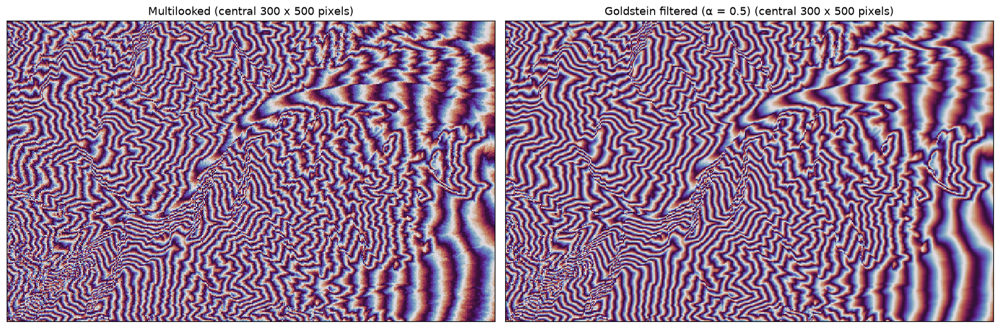

In [16]:
# a central window of 300 x 500 pixels
crop = (slice(ifg.shape[0] // 2 - 150, ifg.shape[0] // 2 + 150), slice(ifg.shape[1] // 2 - 250, ifg.shape[1] // 2 + 250))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))  # two panels
# before and after Goldstein filtering
for ax, z, t in [(axes[0], ifg, "Multilooked"), (axes[1], filt, f"Goldstein filtered (α = {ALPHA})")]:
    # the wrapped phase in the window
    ax.imshow(np.angle(z[crop]), cmap="twilight", interpolation="none", aspect=asp)
    ax.set(title=t + " (central 300 x 500 pixels)", xticks=[], yticks=[])  # title, no ticks
plt.tight_layout(); plt.show()  # arrange and draw

## SNAPHU unwrapping in TOPO mode

**SNAPHU** (Chen & Zebker, 2001) treats unwrapping as a network-flow optimisation: it finds the
integer cycle counts that make the unwrapped phase most probable given statistical models of how
phase gradients arise. In **TOPO** mode those models come from terrain and the acquisition
geometry: slopes facing the radar can produce *layover*, a sudden phase jump that should be
allowed, while slopes facing away cannot. TOPO mode therefore needs the baseline, slant range,
pixel spacings, number of looks and satellite altitude, which `insar.unwrap_snaphu_topo` writes
into SNAPHU's configuration. Pixels with coherence below 0.2 are masked out of the solution.


In [ ]:
# The following code performs phase unwrapping on the filtered interferogram using SNAPHU in TOPO mode.
# First, we import the _Orbit class to extract the satellite orbit information.
from geolattice.rsense.sar.sentinel1 import _Orbit

# Obtain the satellite orbit object for the reference burst.
orb = _Orbit(pann[REF, BURSTS[0]]["orbit"])

# Compute the satellite's position at the middle of the multi-looked acquisition.
sat = orb.pos(orb.seconds(t_ml[len(t_ml) // 2]))

# Convert the center latitude to radians.
lat_c_r = np.radians(lat_c)

# Calculate the Earth's radius at the scene center using ECEF coordinates.
earth_r = float(np.linalg.norm(sar.llh_to_ecef(lat_c, lon_c, 0.0)))

# Compute the satellite's altitude above the Earth's radius at the scene center.
altitude = float(np.linalg.norm(sat)) - earth_r

# Define the mask for unwrapping: pixels that are valid and have coherence > 0.2.
mask_unw = valid_ml & (coh > 0.2)

# Start the timer to measure how long the unwrapping operation takes.
t0 = time.time()

# Run phase unwrapping with SNAPHU in TOPO mode. Key parameters:
#   filt: Goldstein-filtered interferogram
#   coh: coherence image
#   power: sqrt of the mean product of master and slave intensities
#   wavelength: radar wavelength
#   bperp: perpendicular baseline
#   near_range: slant range to first pixel
#   range_spacing, azimuth_spacing: pixel spacing
#   altitude: satellite altitude above Earth surface
#   earth_radius: Earth's radius at scene center
#   nlooks_range, nlooks_azimuth: number of looks used in respective dimensions
#   mask: valid pixels for unwrapping
unw, conncomp = insar.unwrap_snaphu_topo(
    filt, coh, power=np.sqrt(pm * ps), wavelength=lam, bperp=base[REF, SEC]["bperp"], near_range=near_range,
    range_spacing=dr, azimuth_spacing=da, altitude=altitude, earth_radius=earth_r,
    nlooks_range=LOOKS[1], nlooks_azimuth=LOOKS[0], mask=mask_unw)

# Calculate how long unwrapping took.
t_unw = time.time() - t0

# Create a Series counting the number of pixels in each connected component (excluding 0, which is background).
sizes = pd.Series(conncomp[conncomp > 0]).value_counts()

# Print a summary of the unwrapping: time taken, number of pixels, satellite altitude,
# number of connected components, and what fraction of valid pixels the largest component covers.
print(f"SNAPHU TOPO: {t_unw:.0f} s for {ifg.size:,} pixels; satellite altitude {altitude / 1e3:.0f} km; "
      f"{len(sizes)} connected components, the largest covering {sizes.iloc[0] / valid_ml.sum():.0%} of valid pixels")
 

SNAPHU TOPO: 101 s for 2,233,386 pixels; satellite altitude 700 km; 2 connected components, the largest covering 71% of valid pixels


## Phase to elevation

`back_geocode` also measured how fast the range difference grows with height at every pixel
(by locating points at two constant heights), so the unwrapped phase converts directly:
``h = φ · λ / 4π · dh/dΔR`` (`insar.phase_to_height`). The height of ambiguity map follows from
the same factor. Unwrapped phase is still **relative**, since SNAPHU cannot know the absolute
number of cycles, so the result is tied to a reference: the median difference from NASADEM (the
same DEM used for geometry) over coherent pixels. SNAPHU unwraps each **connected component**
(a region it could unwrap consistently) on its own, so each component gets its own tie. One
constant per component is all the reference DEM contributes; the terrain shape comes from the
interferogram.


height of ambiguity across the AOI (1st-99th percentile): 62.7 to 69.0 m
2 connected components tied to NASADEM (offsets 1837, 1751 m); heights for 74% of valid pixels


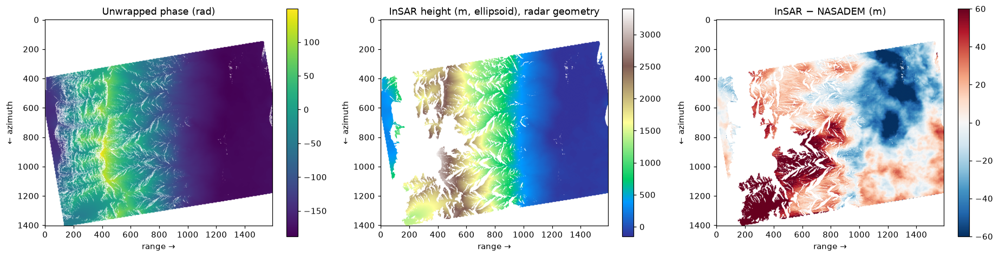

In [ ]:
# Convert the unwrapped phase to height in radar geometry
# - unw: unwrapped phase array
# - lam: radar wavelength
# - G["dheight_ddelta_range"]: slope (per-pixel) relating phase to elevation change
# - reference=G["dem_height"]: tie output heights to DEM at coherent pixels
# - mask=coh > 0.5: restrict to reliable pixels where coherence is high
# - components=conncomp: apply reference tie per connected region
h_radar, offsets = insar.phase_to_height(
    unw, lam, G["dheight_ddelta_range"],
    reference=G["dem_height"], mask=coh > 0.5, components=conncomp
)

# Calculate height of ambiguity (h_a): the phase difference that corresponds to a 2pi (full-cycle) change
# - This determines the vertical sensitivity of the interferogram (meters per 2pi phase change)
h_a_map = G["dheight_ddelta_range"] * lam / 2

# Report the typical range of height of ambiguity across valid pixels in the area of interest
lo, hi = np.nanpercentile(np.abs(h_a_map[valid_ml]), [1, 99])
# range of the height of ambiguity
print(f"height of ambiguity across the AOI (1st-99th percentile): {lo:.1f} to {hi:.1f} m")

# Print information on how many connected components were separately referenced (tied) to the DEM,
# and show the actual offset (vertical tie) applied for each, as well as the fraction of valid pixels for which heights were obtained
print(
    f"{len(offsets)} connected components tied to NASADEM (offsets {', '.join(f'{v:.0f}' for v in offsets.values())} m); "
    f"heights for {np.isfinite(h_radar[valid_ml]).mean():.0%} of valid pixels"
)

# Visualization:
# - Panel 1: unwrapped phase (masked to valid pixels)
# - Panel 2: resulting InSAR-derived elevation map (ellipsoidal heights, radar geometry)
# - Panel 3: difference between InSAR elevation and NASADEM (geometry DEM)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))

# Unwrapped phase image
im = axes[0].imshow(np.where(mask_unw, unw, np.nan), cmap="viridis", aspect=asp)
axes[0].set_title("Unwrapped phase (rad)")  # title
plt.colorbar(im, ax=axes[0], shrink=0.75)  # colour bar

# InSAR height
im = axes[1].imshow(h_radar, cmap="terrain", vmin=-150, vmax=3400, aspect=asp)
axes[1].set_title("InSAR height (m, ellipsoid), radar geometry")  # title
plt.colorbar(im, ax=axes[1], shrink=0.75)  # colour bar

# Height difference (InSAR - DEM)
diff = h_radar - G["dem_height"]
im = axes[2].imshow(diff, cmap="RdBu_r", vmin=-60, vmax=60, aspect=asp)  # InSAR height minus NASADEM
axes[2].set_title("InSAR − NASADEM (m)")  # title
plt.colorbar(im, ax=axes[2], shrink=0.75)  # colour bar

# Add axis labels
for ax in axes:
    ax.set(xlabel="range →", ylabel="← azimuth")  # axis labels

plt.tight_layout()  # arrange
plt.show()  # draw

The height of ambiguity varies from 62.7 to 69.0 m across the AOI (1st-99th percentile). SNAPHU found two connected components: the main one covers 71 % of valid pixels (the valley, the fans and most of the east slope), and a second one covers parts of the western mountains. Each is tied to NASADEM with its own offset (1,837 m and 1,751 m). Heights are obtained for 74 % of valid pixels.

The radar-geometry height map reproduces the Panamint Range and Death Valley. The difference from NASADEM is not noise: it shows broad blobs of −40 to −60 m on the valley floor and +40 to +60 m in the southwest. The *Quality control* section shows where these come from.

## Range-Doppler terrain correction

The heights are still in radar geometry. **Range-Doppler terrain correction**
(`sar.terrain_correct`) builds the output map grid (UTM zone 11N, 30 m), places every map cell at
its DEM height and asks the range-Doppler equations where the satellite saw it: the zero-Doppler
time gives the radar row, the slant range the column. The radar layers are sampled there. Using
the DEM's own heights removes the foreshortening seen in radar geometry; the small dependence of
position on height (about 1.2 m of ground position per metre of height error at this incidence
angle) is negligible for a DEM within tens of metres.


terrain correction onto 739 x 1259 cells of 30 m: 1 s


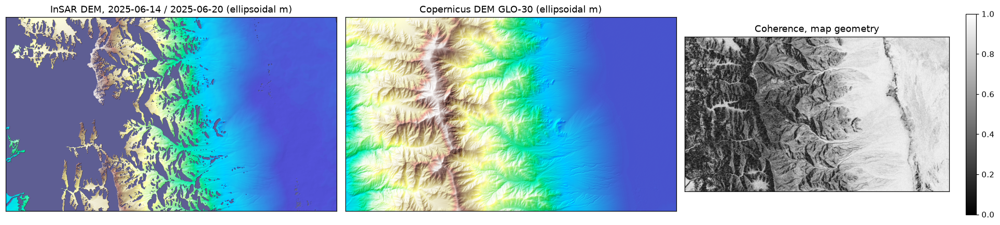

In [ ]:
# Set up output grid in map (UTM) coordinates with 30 m pixels, reprojecting the DEM to UTM zone.
RES = 30
grid = dem_ell.rio.reproject(UTM, resolution=RES, resampling=2)  # the DEM reprojected to UTM at 30 m (bilinear)

# Transform AOI (Area of Interest) corners from lat/lon (EPSG:4326) to UTM coordinates.
from pyproj import Transformer
# south-west AOI corner in UTM
x0, y0 = Transformer.from_crs(4326, UTM, always_xy=True).transform(AOI[0], AOI[1])
# north-east AOI corner in UTM
x1, y1 = Transformer.from_crs(4326, UTM, always_xy=True).transform(AOI[2], AOI[3])

# Clip the grid to the AOI.
grid = grid.sel(x=slice(x0, x1), y=slice(y1, y0))

# Perform range-Doppler terrain correction, mapping InSAR-derived radar-geometry results onto the map grid
# Inputs: dict of InSAR height, coherence, and mask of finite heights; SAR timing; orbit info; grid.
t0 = time.time()
# move each radar-geometry layer onto the UTM grid (range-Doppler terrain correction)
geo = sar.terrain_correct(
    {
        "height": h_radar,             # InSAR-derived elevation in radar geometry (same size as SAR image)
        "coherence": coh,              # InSAR coherence
        "unw_mask": np.isfinite(h_radar).astype("float32"),  # Mask for valid InSAR heights
    },
    t_ml, near_range, dr, pann[REF, BURSTS[0]]["orbit"], grid
)
# grid size and run time
print(f"terrain correction onto {grid.shape[0]} x {grid.shape[1]} cells of {RES} m: {time.time() - t0:.0f} s")

# Load Copernicus GLO-30 DEM (in geoid heights), convert to ellipsoidal heights, and match projection/grid to our output.
ell_file = CACHE / "copdem30_ellipsoid.tif"  # the same DEM above the WGS 84 ellipsoid, saved by an earlier run
if ell_file.exists():  # converted before: read it from the local drive
    cop = rioxarray.open_rasterio(ell_file).squeeze(drop=True)
else:  # first run: add the EGM2008 geoid undulation (PROJ reads the geoid grid online) and save it
    cop = insar.geoid_to_ellipsoid(rioxarray.open_rasterio(CACHE / "copdem30_geoid.tif").squeeze(drop=True), "EGM2008")
    cop.rio.to_raster(ell_file)  # keep it for the next run
cop = cop.rio.reproject_match(grid, resampling=2)  # Copernicus DEM on the same grid

# The grid itself serves as the NASADEM reference in map geometry.
nas = grid

# Prepare for visualization: hillshading parameters.
ls = LightSource(azdeg=315, altdeg=40)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))  # three panels

# Plot: (1) InSAR DEM, (2) Copernicus DEM, both hill-shaded; (3) InSAR coherence map.
for ax, z, t in [
    (axes[0], geo["height"].values, f"InSAR DEM, {REF} / {SEC} (ellipsoidal m)"),
    (axes[1], cop.values, "Copernicus DEM GLO-30 (ellipsoidal m)")
]:
    # Hillshade and DEM elevation
    ax.imshow(
        ls.shade(
            np.nan_to_num(z, nan=np.nanmin(z)),
            cmap=plt.cm.terrain,
            vert_exag=1,
            dx=RES,
            dy=RES,
            vmin=-150,
            vmax=3400,
            blend_mode="overlay"
        )
    )
    # Overlay NaN mask as light gray
    ax.imshow(
        np.where(np.isfinite(z), np.nan, 1),
        cmap="Greys",
        vmin=0,
        vmax=1.5,
        alpha=0.6
    )
    ax.set(title=t, xticks=[], yticks=[])  # title, no ticks

# Third panel: show coherence in map geometry
im = axes[2].imshow(geo["coherence"], cmap="gray", vmin=0, vmax=1)
axes[2].set(title="Coherence, map geometry", xticks=[], yticks=[])  # title, no ticks
plt.colorbar(im, ax=axes[2], shrink=0.75)  # colour bar
plt.tight_layout()  # arrange
plt.show()  # draw

## Quality control

### Masks

Three masks remove heights that cannot be trusted:

- **low coherence** (< 0.35): the phase is mostly noise;
- **layover and shadow** (`sar.layover_shadow_mask` on the DEM, using the ascending pass's
  east-looking geometry): layover mixes several ground points into one radar pixel, shadow has no
  signal;
- **not unwrapped**: pixels outside SNAPHU's connected components, or in components too small to
  tie to the reference.


In [ ]:
# Step-by-step masking and quality control of the InSAR-derived DEM

# 1. Get the satellite heading angle of the reference burst/scene
heading = a0["heading"]

# 2. Calculate the incidence angle map in map geometry; this is needed for layover/shadow masking
inc_map = sar.terrain_correct(
    G["incidence"],      # raw incidence angle grid in radar geometry
    t_ml,                # multilooked time grid
    near_range,          # range calibration (distance to first pixel)
    dr,                  # range pixel spacing
    pann[REF, BURSTS[0]]["orbit"],  # precise orbit for geolocation
    grid                 # target map grid
)

# 3. Compute the layover/shadow mask. 
#    - lsm == 1: layover (geometry distortion where radar sees multiple elevations in one pixel)
#    - lsm == 2: shadow (radar cannot see the ground due to terrain)
lsm = sar.layover_shadow_mask(
    nas.values,                    # DEM values (used for terrain information)
    RES,                           # grid resolution
    heading,                       # satellite heading
    np.nan_to_num(inc_map.values, nan=40.0)  # fill any NaN values in incidence angle with 40°
)

# 4. Define the mask dictionary:
#    - "low coherence (< 0.35)": pixels where interferometric phase coherence is too low
#    - "layover": locations identified as radar layover
#    - "shadow": locations in radar shadow
#    - "not unwrapped or not tied": phase not unwrapped, or not tied to reference component
masks = {
    "low coherence (< 0.35)": geo["coherence"].values < 0.35,
    "layover": lsm == 1,
    "shadow": lsm == 2,
    "not unwrapped or not tied": ~(geo["unw_mask"].values > 0.5)
}

# 5. Collect the "inside" mask, which is True for valid (finite) DEM pixels
inside = np.isfinite(nas.values)

# 6. Pixel selection: keep only pixels that are inside the AOI and pass all mask tests (are not masked by any of the masks)
keep = inside & ~np.any(list(masks.values()), axis=0)

# 7. Mask the DEM using this combined mask.
dem1 = geo["height"].where(keep)

# 8. For each mask (and the final 'kept'), print the fraction of the AOI masked/kept
mask_summary = {k: f"{np.mean(v[inside]):.1%}" for k, v in masks.items()}
mask_summary["kept"] = f"{keep[inside].mean():.1%}"  # share of the AOI that is kept
print(pd.Series(mask_summary, name="share of the AOI").to_string())  # print the shares

low coherence (< 0.35)       26.9%
layover                       0.1%
shadow                        0.1%
not unwrapped or not tied    34.7%
kept                         63.4%


### Validation against Copernicus DEM and ICESat-2

Copernicus DEM GLO-30 (from TanDEM-X, 2011-2015) is independent of everything used so far
(NASADEM placed the pixels and supplied one constant). ICESat-2's ATL06 land segments (20 m along
track, from the photon-counting laser) are a still more direct reference: SlideRule computes them
on demand from the photon data, in WGS84 ellipsoidal heights, so they compare directly.


In [ ]:
# ------------------------------------------------------------------------------
# Purpose: Validate the generated InSAR DEM against independent elevation references:
#          - ICESat-2 ATL06 segments (photon-counting lidar, ~20m spots)
#          - NASADEM (Shuttle Radar Topography Mission based DEM)
#          - Copernicus DEM GLO-30 (based on TanDEM-X)
#          The comparison is performed by extracting DEM values at the ICESat-2 points' locations,
#          filtering for high-quality samples, and computing error statistics.
# ------------------------------------------------------------------------------

# 1. Try to load already-downloaded and pre-processed ICESat-2 points (parquet file)
is2_file = CACHE / "icesat2_atl06sr_2024_2025.parquet"
if is2_file.exists():  # reuse the cached ICESat-2 points
    import geopandas as gpd  # vector data
    is2 = gpd.read_parquet(is2_file)  # read them
else:
    # If not available, query and download the ATL06-SR land segments using SlideRule
    from sliderule import icesat2, sliderule
    sliderule.init(verbose=False)  # start a SlideRule session
    # Define polygon representing area of interest (AOI) from bounding box AOI
    region = [{"lon": x, "lat": y} for x, y in [
        (AOI[0], AOI[1]), (AOI[2], AOI[1]), (AOI[2], AOI[3]),
        (AOI[0], AOI[3]), (AOI[0], AOI[1])
    ]]
    # Query ICESat-2 ATL06 products for given time interval and AOI
    is2 = icesat2.atl06p({
        "poly": region,
        "t0": "2024-01-01T00:00:00Z", "t1": "2025-12-31T23:59:59Z",
        "srt": icesat2.SRT_LAND,        # only land segments
        "cnf": 4,                       # minimum signal confidence ("land ice")
        "len": 40.0,                    # segment length [m]
        "res": 20.0,                    # along-track spacing [m]
        "ats": 20.0,                    # along-track step [m]
        "cnt": 10                       # minimum number of photons
    })
    is2.to_parquet(is2_file)  # Save to disk for future runs

# 2. Filter segments for quality (height uncertainty < 1.0 m), and project to UTM
is2 = is2[(is2.h_sigma < 1.0)].to_crs(UTM)

# 3. Extract X and Y coordinates of segments (for sampling raster data at points)
pts = (np.asarray(is2.geometry.x), np.asarray(is2.geometry.y))

# 4. Helper function: extract raster data at ICESat-2 point locations
def at_points(da):
    # da: xarray DataArray with dimensions ('y','x')
    # Returns 1-D array of the variable's values at ICESat-2 points (nearest grid cell)
    return da.sel(
        x=xr.DataArray(pts[0], dims="p"),
        y=xr.DataArray(pts[1], dims="p"),
        method="nearest"
    ).values

# 5. Further filter: Ensure ICESat-2 points fall within grid extent (avoid sampling outside DEM)
ok_pts = (
    (pts[0] > float(grid.x.min())) & (pts[0] < float(grid.x.max())) &
    (pts[1] > float(grid.y.min())) & (pts[1] < float(grid.y.max()))
)
is2 = is2[ok_pts]  # keep only points inside the grid
pts = (pts[0][ok_pts], pts[1][ok_pts])  # their coordinates

# 6. Compute local terrain slope (in degrees) from NASADEM
slope = np.degrees(np.arctan(np.hypot(*np.gradient(nas.values, RES))))
slope_da = nas.copy(data=slope)  # slope as a DataArray on the NASADEM grid

# number of points and ground tracks
print(f"ICESat-2 ATL06-SR segments in the AOI: {len(is2):,} from {is2.rgt.nunique()} reference ground tracks")

# 7. For each DEM (InSAR, NASADEM, Copernicus), extract values at ICESat-2 points.
#    Compute error statistics versus ICESat-2.
rows = {}
for name, z in [  # the three DEMs compared with ICESat-2
    ("InSAR, one pair (masked)", dem1),
    ("NASADEM (geometry DEM)", nas),
    ("Copernicus GLO-30", cop)
]:
    # key: "<DEM name> vs ICESat-2"
    rows[name + " vs ICESat-2"] = insar.dem_error_stats(at_points(z), is2.h_mean.values)

# 8. Additionally, compare InSAR DEM to Copernicus DEM directly (pixel-wise, over full DEM)
rows["InSAR, one pair (masked) vs Copernicus"] = insar.dem_error_stats(dem1, cop)

# 9. Format results as DataFrame (methods report bias, median, NMAD, etc.) and round to 0.01
val = pd.DataFrame(rows).T.round(2)
val  # show the table

ICESat-2 ATL06-SR segments in the AOI: 67,320 from 4 reference ground tracks


,n,bias,median,std,rmse,nmad,le90
"InSAR, one pair (masked) vs ICESat-2",47376.0,-4.45,-0.92,34.03,34.32,30.25,59.39
NASADEM (geometry DEM) vs ICESat-2,67320.0,0.35,0.33,5.97,5.98,2.92,9.82
Copernicus GLO-30 vs ICESat-2,67320.0,0.08,0.14,4.42,4.42,1.53,7.03
"InSAR, one pair (masked) vs Copernicus",573045.0,-1.43,-1.27,36.85,36.88,34.69,63.05


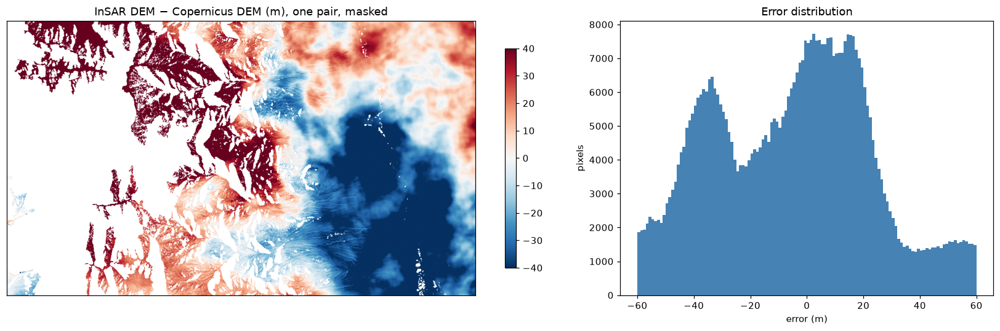

n  median  nmad
             g                             
by slope     0–5°      271807   -19.2  33.2
             5–15°     135709    -7.5  32.1
             15–25°     82280    18.6  32.6
             25–35°     73476    24.9  31.0
             > 35°       9773    39.5  29.6
by coherence 0.35–0.5   54079    31.8  33.2
             0.5–0.65   93774    20.2  33.7
             0.65–0.8   88031     4.1  30.8
             0.8–1     337161   -16.5  31.3

In [ ]:
# Calculate the difference between the InSAR DEM and Copernicus DEM.
err = dem1 - cop

# Bin the terrain slope values into categories for later analysis.
# sl_bins will label each pixel by which slope range it falls into.
sl_bins = pd.cut(
    slope_da.values.ravel(),
    [0, 5, 15, 25, 35, 90],
    labels=["0-5°", "5-15°", "15-25°", "25-35°", "> 35°"]
)

# Bin the coherence values into categories, covering the most common range for meaningful InSAR measurements.
co_bins = pd.cut(
    geo["coherence"].values.ravel(),
    [0.35, 0.5, 0.65, 0.8, 1.0],
    labels=["0.35-0.5", "0.5-0.65", "0.65-0.8", "0.8-1"]
)

# Flatten the DEM error map so we can compare to the binned slope & coherence arrays.
e = err.values.ravel()

# Create two DataFrames: one associates each error value with its slope bin,
# the other associates error values with their coherence bin.
# For both, drop any values where the group is missing, and then group by each bin.
# For each group, calculate:
#   - n: number of pixels in the group
#   - median: median of DEM error in group
#   - nmad: normalized median absolute deviation (robust spread statistic)
by = pd.concat({
    "by slope": pd.DataFrame({"e": e, "g": sl_bins})
        .dropna()
        .groupby("g", observed=True)["e"]
        .agg(
            n="size",
            median="median",
            nmad=lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))
        ),
    "by coherence": pd.DataFrame({"e": e, "g": co_bins})
        .dropna()
        .groupby("g", observed=True)["e"]
        .agg(
            n="size",
            median="median",
            nmad=lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))
        )
}).round(1)

# Plot the error map and error histogram
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})

# Left: visualize spatial distribution of DEM error (masked by the processing above)
im = axes[0].imshow(
    err,
    cmap="RdBu_r",
    vmin=-40,
    vmax=40
)
axes[0].set(  # labels and title
    title="InSAR DEM − Copernicus DEM (m), one pair, masked",
    xticks=[],
    yticks=[]
)
plt.colorbar(im, ax=axes[0], shrink=0.8)  # colour bar

# Right: histogram of error values, showing distribution across AOI
axes[1].hist(
    e[np.isfinite(e)],
    bins=np.arange(-60, 61, 1),
    color="steelblue"
)
axes[1].set(  # labels and title
    xlabel="error (m)",
    ylabel="pixels",
    title="Error distribution"
)
plt.tight_layout()  # arrange
plt.show()  # draw

# Display the statistics by slope and by coherence
by

**One pair, as unwrapped.** After the masks (26.9 % low coherence, 34.7 % not unwrapped or not tied, 0.1 % each layover and shadow; 63.4 % of the AOI kept), the 14→20 June DEM has a bias of −4.5 m and an NMAD of 30.3 m against 47,376 ICESat-2 segments (RMSE 34.3 m, LE90 59.4 m). The two reference DEMs agree with ICESat-2 to 2.9 m (NASADEM) and 1.5 m (Copernicus) NMAD. The errors depend on terrain: the median error is −19 m on slopes under 5° and +40 m on slopes over 35°, and it is −17 m where coherence exceeds 0.8 but +32 m where it is 0.35-0.5. Coherence and slope both follow elevation here (flat, coherent valley floor; steep, less coherent mountains), so these patterns point to an error that grows with elevation.

### The other two pairs

`run_pair` repeats Steps 4-12 for a pair with exactly the functions used above (back-geocoding,
ESD, flat-Earth removal, deburst, multilook, Goldstein, SNAPHU TOPO, phase to height, terrain
correction), and the same masks are applied to each result.


In [ ]:
# The function and following code below perform all the necessary processing for InSAR DEM generation from a pair of radar acquisitions.
# This includes all the main steps in a standard repeat-pass SAR interferometry chain, as well as error quantification and summary.

def run_pair(ref_date, sec_date):
    """
    Run the full InSAR processing chain for one pair of SAR acquisitions.
    Returns geocoded layers (height, coherence, sigma, mask).

    Steps (each are standard in repeat-pass InSAR production):
    1. Collect input SLCs, orbit annotation, burst geometry metadata for the reference date.
    2. Co-register the reference and secondary images (coregister step per burst).
    3. Enhanced Spectral Diversity (ESD): Estimate azimuth shift, adjust co-registration for accuracy.
    4. Flatten interferogram using flat-earth phase removal.
    5. Deburst and multilook: combine data across bursts, average pixels in range/azimuth to reduce noise.
    6. Calculate interferogram and power images, as well as geometric metadata layers.
    7. Compute coherence (quality measure) and flag valid pixels.
    8. Apply optional Goldstein phase filtering to reduce noise.
    9. Unwrap phase using SNAPHU in topography mode, providing coherence and geometry to guide the solution.
    10. Convert unwrapped phase to height using geometry.
    11. Estimate standard deviation of height ("sigma") from coherence and geometry.
    12. Geocode (terrain-correct): warp results to map grid.
    """
    # 1. Extract inputs for all bursts (rf: reference image, ids: burst IDs, an: annotation)
    rf = [slc[ref_date, b] for b in BURSTS]
    ids = [idx[ref_date, b] for b in BURSTS]  # burst index of each burst on the reference date
    an = [pann[ref_date, b] for b in BURSTS]  # orbit-corrected annotation of each burst

    # 2. Coregister reference and secondary, per burst
    gm, sr = {}, {}  # gm: geometry metadata, sr: secondary SLCs coregistered
    for b in BURSTS:  # first pass: coregister each burst
        gm[b], sr[b] = coregister(ref_date, sec_date, b)  # back-geocoding and resampling

    # 3. Estimate azimuth shift using ESD, apply as extra shift in coregistration for accuracy
    e = sar.esd_azimuth_shift(
        rf, [sr[b] for b in BURSTS], an[0], ids, col0=cols[ref_date, BURSTS[0]][0], anns=an
    )
    for b in BURSTS:  # second pass, with the ESD azimuth shift
        # resample again with the shift
        sr[b] = coregister(ref_date, sec_date, b, extra_line_shift=e["shift_lines"])[1]

    # 4. Form interferogram and remove flat earth phase
    #    np.nan_to_num ensures numerical safety in case of nans
    full = {
        b: np.nan_to_num(
            slc[ref_date, b]
            * np.conj(sr[b])
            * np.exp(-1j * insar.flat_earth_phase(gm[b]["flat_delta_range"], lam))
        ).astype("complex64")
        for b in BURSTS
    }

    # Helper: Deburst (combine all bursts) and multilook (average/pixel size reduction)
    def dml(layer):
        img, t = sar.deburst([layer[b] for b in BURSTS], an[0], ids, anns=an)  # join the bursts
        if np.iscomplexobj(img):  # complex layers: complex multilook
            return insar.multilook_complex(img, LOOKS), t  # return image and times
        else:
            return sar.multilook(img.astype("float64"), LOOKS), t  # real layers: float multilook

    # 5. Deburst+multilook: main interferogram (z), power images (p1, p2), geom layers (gg)
    z, tf = dml(full)
    p1, _ = dml({b: np.abs(slc[ref_date, b]) ** 2 for b in BURSTS})         # power of reference
    p2, _ = dml({b: np.abs(sr[b]) ** 2 for b in BURSTS})                   # power of secondary
    # geometry layers on the multilooked grid
    gg = {k: dml({b: gm[b][k] for b in BURSTS})[0] for k in ("dem_height", "dheight_ddelta_range")}

    # 6. Calculate time grid of multilooked product
    tm = tf[: (tf.size // LOOKS[0]) * LOOKS[0]].astype("int64").reshape(-1, LOOKS[0]).mean(1).astype("datetime64[ns]")

    # 7. Compute mask for valid pixels: nonzero amplitude and geometry present
    v = (np.abs(z) > 0) & (p1 > 0) & (p2 > 0) & np.isfinite(gg["dem_height"])

    # 8. Compute coherence: normalized cross-correlation of multilooked complex image
    c = np.where(
        v, np.clip(np.abs(box(z)) / np.sqrt(box(p1) * box(p2) + 1e-30), 0, 1), 0
    )

    # 9. Apply Goldstein filtering (optional), filter noisy pixels
    fz = insar.goldstein_filter(
        np.where(v, z / (np.abs(z) + 1e-30), 0), alpha=ALPHA, patch=32, overlap=8
    )

    # 10. Calculate near range, a geometric key value for further geocoding
    nr = float(
        an[0]["slant_range_time"] * sar.SPEED_OF_LIGHT / 2
        + (cols[ref_date, BURSTS[0]][0] + (LOOKS[1] - 1) / 2) * an[0]["range_pixel_spacing"]
    )

    # 11. Phase unwrapping: convert measured phase to continuous surface, using mask and coherence
    u, cc = insar.unwrap_snaphu_topo(
        fz,
        c,
        power=np.sqrt(p1 * p2),
        wavelength=lam,
        bperp=base[ref_date, sec_date]["bperp"],
        near_range=nr,
        range_spacing=dr,
        azimuth_spacing=da,
        altitude=altitude,
        earth_radius=earth_r,
        nlooks_range=LOOKS[1],
        nlooks_azimuth=LOOKS[0],
        mask=v & (c > 0.2),
    )

    # 12. Convert unwrapped phase to height using geometric sensitivity factors
    h, _ = insar.phase_to_height(
        u, lam, gg["dheight_ddelta_range"], reference=gg["dem_height"], mask=c > 0.5, components=cc
    )

    # Estimate standard deviation of height error from coherence and geometry
    sig = insar.height_std(c, 9 * LOOKS[0] * LOOKS[1], gg["dheight_ddelta_range"] * lam / 2)

    # 13. Geocode/terrain correct: warp products onto output DEM grid, add orbit/time info
    return sar.terrain_correct(
        {
            "height": h,
            "coherence": c,
            "sigma": sig,
            "unw_mask": np.isfinite(h).astype("float32"),
        },
        tm,
        nr,
        dr,
        an[0]["orbit"],
        grid,
    )

# ---- Run the code above for all image pairs, organize products and collect error/statistics ----

t0 = time.time()

# The first pair is precomputed/"geo", build its Dataset structure
maps = {
    (REF, SEC): xr.Dataset(
        {
            "height": geo["height"],
            "coherence": geo["coherence"],
            "unw_mask": geo["unw_mask"],
            # sigma is calculated from coherence and h_a_map, terrain-corrected to grid
            "sigma": sar.terrain_correct(
                insar.height_std(coh, 9 * LOOKS[0] * LOOKS[1], h_a_map),
                t_ml,
                near_range,
                dr,
                pann[REF, BURSTS[0]]["orbit"],
                grid,
            ),
        }
    )
}

# For each other pair, compute and store InSAR-derived map products (run the workflow above)
for pair in PAIRS:
    if pair not in maps:  # process each pair only once
        maps[pair] = run_pair(*pair)  # run the whole chain for this pair

print(f"two more pairs processed in {time.time() - t0:.0f} s")  # run time

# Build masks for valid points in area of interest (inside), sufficient coherence, no layover/shadow/mask, good unwrapping
keep = {
    p: inside & (m["coherence"].values >= 0.35) & (lsm == 0) & (m["unw_mask"].values > 0.5)
    for p, m in maps.items()
}

# Extract just the (masked) heights & sigma for further analysis
heights = {p: m["height"].where(keep[p]) for p, m in maps.items()}
sigmas = {p: m["sigma"].where(keep[p]) for p, m in maps.items()}  # height uncertainty of each pair, masked

# Create a readable label for each pair with dates and perpendicular baseline
label = {
    p: f"{p[0][5:]} / {p[1][5:]} (B⊥ {base[p]['bperp']:+.0f} m)" for p in PAIRS
}

# For each pair, compute error statistics (against independent ICESat-2 validation points)
# as well as the fraction of AOI pixels kept, and show that as a summary table
pd.DataFrame(
    {
        label[p]: insar.dem_error_stats(at_points(heights[p]), is2.h_mean.values)
        | {"kept": float(keep[p][inside].mean())}
        for p in PAIRS
    }
).T[["n", "kept", "bias", "nmad", "rmse", "le90"]].round(3)
# End of rewritten section

two more pairs processed in 539 s


,n,kept,bias,nmad,rmse,le90
06-08 / 06-14 (B⊥ +255 m),49685.0,0.680,-3.358,33.977,32.409,53.362
06-14 / 06-20 (B⊥ -273 m),47376.0,0.634,-4.451,30.248,34.323,59.389
06-20 / 06-26 (B⊥ +264 m),47714.0,0.637,-4.150,35.386,36.384,61.904


The other two pairs take about 9 minutes together. All three pairs give similar single-pair errors (NMAD 30-35 m, bias −3 to −4.5 m), with 63-68 % of the AOI kept.

### Diagnosing the error: the troposphere

The errors of a single pair are far larger than phase noise predicts (`insar.height_std` gives
about a metre at this coherence), and they are smooth: a ramp across the scene and a part that
grows with elevation. Both are the signature of the **troposphere**. Radar waves are delayed by
water vapour; a delay *difference* of 1 cm between the two dates shifts the phase by 4π/λ × 1 cm
≈ 2.3 rad, which a height of ambiguity of 65 m turns into about 23 m of height. The
**stratified** part of the delay depends on how much air lies above the ground, so it changes
with elevation; turbulence adds blobs a few kilometres across.

`insar.detrend_heights` fits each pair's difference from NASADEM (the geometry DEM, not used for
validation) with a plane plus a term proportional to elevation, over coherent unmasked ground,
and removes it. This transfers NASADEM's longest wavelengths into the InSAR DEM, so the InSAR
DEM's own contribution is the shorter-wavelength relief; ICESat-2 and Copernicus DEM stay
independent checks. A weather-model correction (ERA5, GACOS) is the alternative that does not
use a reference DEM.


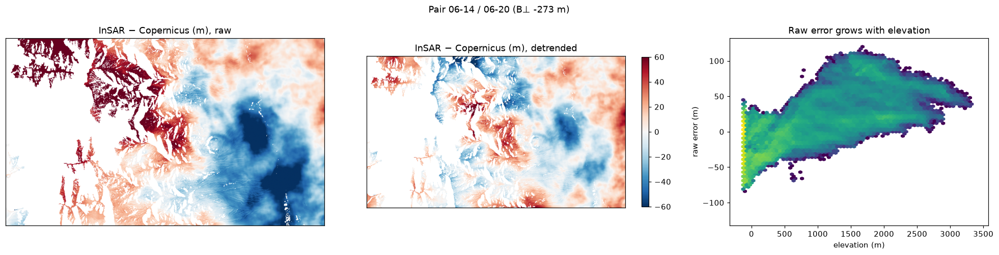

,elevation term (m per km),ramp east-west (m),ramp north-south (m),NMAD raw (m),NMAD detrended (m),RMSE raw (m),RMSE detrended (m)
06-08 / 06-14 (B⊥ +255 m),-7.9,-123.8,-4.8,34.0,17.4,32.4,20.0
06-14 / 06-20 (B⊥ -273 m),31.1,-5.1,-59.8,30.2,17.6,34.3,19.1
06-20 / 06-26 (B⊥ +264 m),46.7,43.5,-51.2,35.4,21.9,36.4,20.6


In [ ]:
# --- Remove long-wavelength atmospheric error (mainly due to the troposphere) from InSAR DEMs ---
# We want to fit and remove smooth trends in the InSAR heights by comparing them with a reference DEM (NASADEM)
# For each InSAR pair:
#   - Fit a model of the difference to the reference DEM as a plane + elevation trend using insar.detrend_heights
#   - Store the detrended DEM (trend removed) and the fitted coefficients for further analysis
detr = {}   # stores detrended heights for each pair
coefs = {}  # stores estimated trend coefficients for each pair
for p in PAIRS:  # each pair
    # Only fit over points that are high-coherence and not masked
    detr[p], coefs[p] = insar.detrend_heights(heights[p], nas, keep[p] & (maps[p]["coherence"].values > 0.5))

# --- Summarize error statistics before and after detrending for each pair ---
# For each pair: 
#     - Calculate accuracy statistics (nmad = normalized MAD, rmse, etc.) for raw and detrended DEMs versus ICESat-2 points
#     - Save relevant ramp/elevation coefficients from the fit
rows = {}
for p in PAIRS:  # each pair
    # Error stats for original heights vs. ICESat-2
    raw_s = insar.dem_error_stats(at_points(heights[p]), is2.h_mean.values)
    # Error stats for detrended heights vs. ICESat-2
    det_s = insar.dem_error_stats(at_points(detr[p]), is2.h_mean.values)
    # Store statistics and trend coefficients in a summary dict
    rows[label[p]] = {
        "elevation term (m per km)": coefs[p]["elevation"] * 1000,  # Convert slope from m/m to m/km
        "ramp east-west (m)": coefs[p]["x"],
        "ramp north-south (m)": coefs[p]["y"],
        "NMAD raw (m)": raw_s["nmad"],
        "NMAD detrended (m)": det_s["nmad"],
        "RMSE raw (m)": raw_s["rmse"],
        "RMSE detrended (m)": det_s["rmse"]
    }

# Create a summary table (DataFrame) of statistics and trend terms for all pairs
detrend_table = pd.DataFrame(rows).T.round(1)

# --- Visualize the effects of trend removal for the main (reference) pair ---
main = (REF, SEC)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.8]})  # three panels

# Show InSAR minus Copernicus DEM: (a) before and (b) after detrending
for ax, z, t in [(axes[0], heights[main], "raw"), (axes[1], detr[main], "detrended")]:
    im = ax.imshow(z - cop, cmap="RdBu_r", vmin=-60, vmax=60)  # the pair's height minus Copernicus
    ax.set(title=f"InSAR − Copernicus (m), {t}", xticks=[], yticks=[])  # title, no ticks
plt.colorbar(im, ax=axes[1], shrink=0.8)  # colour bar

# Overall figure title: the selected pair with its label
fig.suptitle(f"Pair {label[main]}")

# (c) Plot a hexbin: error (InSAR - Cop) vs. reference DEM elevation - showing trend with elevation
e = (heights[main] - cop).values
ok = np.isfinite(e)  # pixels with a valid error
axes[2].hexbin(  # error against terrain slope as a density plot
    cop.values[ok], e[ok],
    gridsize=70, bins="log",
    extent=(-150, 3400, -120, 120),
    cmap="viridis"
)
axes[2].set(  # labels and title
    xlabel="elevation (m)",
    ylabel="raw error (m)",
    title="Raw error grows with elevation"
)

plt.tight_layout()  # arrange
plt.show()  # draw

# --- Display the summary statistics table ---
detrend_table

The fitted trends differ from pair to pair. The elevation term is −8 m per km of height for 8→14 June, +31 for 14→20 and +47 for 20→26, and the ramps across the scene reach up to 124 m. A geometric error (in the baseline, say) would give the same trend in every pair; trends that change from pair to pair point to the atmosphere, which changes from date to date. Removing them roughly halves the NMAD of every pair (30.2 → 17.6 m for the main pair, and to 17.4 and 21.9 m for the others). The maps show what remains: turbulent blobs a few kilometres across, which no plane-plus-elevation fit can remove.

### Averaging several pairs

Averaging pairs reduces atmospheric error only if the pairs' errors are **independent**. Our three
pairs are consecutive (8→14, 14→20, 20→26 June), so neighbours share a date and with it that
date's atmosphere. Because the baselines alternate in sign (+, −, +), a shared date's delay
enters both neighbouring pairs' heights with the *same* sign, so it adds up instead of
cancelling. The correlation of the pairs' errors shows this directly, and suggests the better
combination: the two pairs with **no date in common** (8→14 and 20→26 June).
`insar.combine_heights` averages with inverse-variance weights from each pixel's coherence.


In [ ]:
# First, identify the pixels that have valid (finite) values for all three detrended InSAR pairs
# as well as for the Copernicus DEM. This mask ('common') ensures comparisons only over shared, valid data.
common = np.all([np.isfinite(detr[p].values) for p in PAIRS], axis=0) & np.isfinite(cop.values)

# Calculate the correlation matrix between the error maps (detrended InSAR minus Copernicus) for all pairs,
# using only pixels that are valid in every pair and Copernicus. Display as a table, labelling with pair names.
corr = pd.DataFrame(
    np.corrcoef([(detr[p] - cop).values[common] for p in PAIRS]),
    index=[label[p] for p in PAIRS],
    columns=[label[p] for p in PAIRS]
).round(2)
display(corr)  # show the correlation matrix

# Define combinations of InSAR pairs to evaluate:
# - All three pairs together
# - Only pairs with no shared date (i.e., independent atmospheric errors)
# - The two consecutive pairs (share one date each)
combos = {
    "all three pairs": PAIRS,
    "8→14 + 20→26 June (no shared date)": [PAIRS[0], PAIRS[2]],
    "8→14 + 14→20 June": [PAIRS[0], PAIRS[1]],
    "14→20 + 20→26 June": [PAIRS[1], PAIRS[2]],
}

rows, avgs = {}, {}  # statistics and averaged DEMs per combination

# For each pair combination, create a weighted average DEM using insar.combine_heights,
# then compute error statistics compared to ICESat-2 ground truth.
# 'kept' gives the fraction of valid (unmasked) pixels in the AOI for the combined DEM.
for name, ps in combos.items():
    # inverse-variance weighted average of the pairs and its uncertainty
    h, s_ = insar.combine_heights([detr[p] for p in ps], [sigmas[p] for p in ps])
    avgs[name] = grid.copy(data=h.astype("float32"))  # the average as a DataArray on the grid
    rows[name] = (  # error statistics against ICESat-2 plus the kept share
        insar.dem_error_stats(at_points(avgs[name]), is2.h_mean.values)
        | {"kept": float(np.isfinite(h[inside]).mean())}
    )

# Additionally, compute error statistics for each single pair separately
for p in PAIRS:
    rows[f"single pair {label[p]}"] = (  # the same statistics for each single pair
        insar.dem_error_stats(at_points(detr[p]), is2.h_mean.values)
        | {"kept": float(keep[p][inside].mean())}
    )

# Pack all results into a DataFrame for summary, showing n (number), kept (fraction),
# bias, NMAD, RMSE, and LE90 for each DEM combination.
pairs_val = pd.DataFrame(rows).T[["n", "kept", "bias", "nmad", "rmse", "le90"]].round(2)

# Set 'avg' as the averaged DEM using the two independent pairs (recommended option).
avg = avgs["8→14 + 20→26 June (no shared date)"]

# Show the summary statistics table.
pairs_val

,06-08 / 06-14 (B⊥ +255 m),06-14 / 06-20 (B⊥ -273 m),06-20 / 06-26 (B⊥ +264 m)
06-08 / 06-14 (B⊥ +255 m),1.00,0.26,-0.10
06-14 / 06-20 (B⊥ -273 m),0.26,1.00,0.86
06-20 / 06-26 (B⊥ +264 m),-0.10,0.86,1.00


,n,kept,bias,nmad,rmse,le90
all three pairs,50505.0,0.67,-1.32,14.93,16.28,27.48
8→14 + 20→26 June (no shared date),50252.0,0.67,-0.78,14.31,15.18,25.04
8→14 + 14→20 June,50202.0,0.67,-1.08,14.76,16.86,28.62
14→20 + 20→26 June,48502.0,0.63,-1.67,18.75,19.15,31.59
single pair 06-08 / 06-14 (B⊥ +255 m),49685.0,0.68,-0.02,17.43,20.03,35.34
single pair 06-14 / 06-20 (B⊥ -273 m),47376.0,0.63,-1.85,17.57,19.08,32.92
single pair 06-20 / 06-26 (B⊥ +264 m),47714.0,0.64,-1.70,21.95,20.63,32.73


The correlations bear out the shared-date argument. The two pairs sharing 20 June correlate at 0.86 (that date evidently had a strong atmospheric delay), the two sharing 14 June at 0.26, and the two pairs with no date in common at −0.10, independent. Averaging accordingly:

- the two **independent** pairs (8→14 + 20→26 June) give the best DEM: NMAD 14.3 m, RMSE 15.2 m, LE90 25.0 m, bias −0.8 m;
- all three pairs give 14.9 m, slightly worse, because 14→20 brings in 20 June's delay a second time;
- 14→20 + 20→26, which share that date, give 18.8 m, worse than the better single pairs.

The final DEM uses the two independent pairs, chosen on that principle before looking at these numbers. With more dates, choosing pairs that share no date (or many pairs in a network) is what really suppresses the atmosphere.

### Filling the gaps

Masked pixels leave voids: 33 % of the AOI, mostly the foreshortened, west-facing (radar-facing) slopes of the Panamint Range, where coherence is low, and parts of the second connected component that fall below the coherence threshold. `insar.fill_dem_voids` fills them with the
**delta-surface** method: the difference between the InSAR DEM and a reference DEM is interpolated
into each void from its edges and added back to the reference, so the fill takes its shape from
the reference terrain but meets the InSAR surface without a step. NASADEM is used as the fill
source, so Copernicus DEM and ICESat-2 remain independent for the final check.


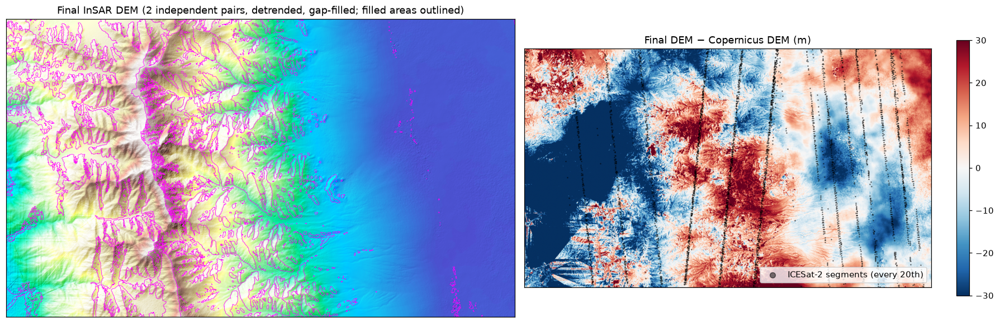

saved outputs/insar_death_valley/insar_dem_death_valley_2025_egm2008.tif (EGM2008 heights) and the WGS84 ellipsoidal version; 33.3% of the AOI filled


,n,bias,nmad,rmse,le90
"InSAR DEM, gap-filled (all pixels)",67320.0,-1.88,16.22,18.49,29.47
measured pixels only,50252.0,-0.78,14.31,15.18,25.04
filled pixels only,17068.0,-5.09,25.07,25.90,44.91
vs Copernicus DEM (all pixels),930401.0,-6.63,18.99,25.15,40.09
NASADEM,67320.0,0.35,2.92,5.98,9.82
Copernicus GLO-30,67320.0,0.08,1.53,4.42,7.03


In [ ]:
# Fill voids (gaps) in the averaged InSAR DEM using the delta-surface method,
# with NASADEM as a reference, and set a maximum search distance for interpolation.
final = insar.fill_dem_voids(avg, nas, max_search_distance=200)

# Convert the gap-filled DEM from the WGS84 ellipsoid heights to EGM2008 geoid heights.
final_geoid = insar.geoid_to_ellipsoid(final, "EGM2008", inverse=True)

# Save both DEM versions to disk: one with EGM2008 heights, one with WGS84 ellipsoidal heights.
final_geoid.rio.write_nodata(np.nan).rio.to_raster(OUT / "insar_dem_death_valley_2025_egm2008.tif")
# save the WGS 84 ellipsoid version
final.rio.write_nodata(np.nan).rio.to_raster(OUT / "insar_dem_death_valley_2025_wgs84.tif")

# Identify which pixels in the AOI were filled (not originally in avg, but inside the valid mask).
filled = ~np.isfinite(avg.values) & inside

# Compile validation statistics:
# - For all pixels,
# - For only measured (original, unfilled) pixels,
# - For just filled pixels,
# - For direct comparison with Copernicus DEM,
# - For NASADEM and Copernicus GLO-30 DEMs against ICESat-2 ground truth.
final_rows = {
    "InSAR DEM, gap-filled (all pixels)": insar.dem_error_stats(at_points(final), is2.h_mean.values),
    "  measured pixels only": insar.dem_error_stats(at_points(final.where(~filled)), is2.h_mean.values),
    "  filled pixels only": insar.dem_error_stats(at_points(final.where(filled)), is2.h_mean.values),
    "  vs Copernicus DEM (all pixels)": insar.dem_error_stats(final, cop),
    "NASADEM": insar.dem_error_stats(at_points(nas), is2.h_mean.values),
    "Copernicus GLO-30": insar.dem_error_stats(at_points(cop), is2.h_mean.values)
}
# Summarize the results as a DataFrame showing number of points, bias, NMAD, RMSE, and LE90.
final_val = pd.DataFrame(final_rows).T[["n", "bias", "nmad", "rmse", "le90"]].round(2)

# Visualization:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

# Left: Show hillshaded final DEM, with filled voids outlined in magenta.
axes[0].imshow(
    ls.shade(
        np.nan_to_num(final.values, nan=0),
        cmap=plt.cm.terrain,
        vert_exag=1,
        dx=RES, dy=RES,
        vmin=-150, vmax=3400,
        blend_mode="overlay"
    )
)
axes[0].contour(filled, levels=[0.5], colors="magenta", linewidths=0.5)  # outline of the filled areas
axes[0].set(  # labels and title
    title="Final InSAR DEM (2 independent pairs, detrended, gap-filled; filled areas outlined)",
    xticks=[],
    yticks=[]
)

# Right: Show difference between final DEM and Copernicus DEM. Also plot ICESat-2 points.
im = axes[1].imshow(final - cop, cmap="RdBu_r", vmin=-30, vmax=30)
gx = (pts[0] - float(grid.x.min())) / RES  # point x positions in pixels
gy = (float(grid.y.max()) - pts[1]) / RES  # point y positions in pixels
axes[1].scatter(  # the ICESat-2 points
    gx[::20], gy[::20], s=0.4, c="k", alpha=0.5, label="ICESat-2 segments (every 20th)"
)
axes[1].set(title="Final DEM − Copernicus DEM (m)", xticks=[], yticks=[])  # title, no ticks
axes[1].legend(loc="lower right", markerscale=10)  # legend
plt.colorbar(im, ax=axes[1], shrink=0.8)  # colour bar

plt.tight_layout()  # arrange
plt.show()  # draw

# Report file save locations and the percentage of AOI that was gap-filled.
print(
    f"saved {OUT / 'insar_dem_death_valley_2025_egm2008.tif'} (EGM2008 heights) and the WGS84 ellipsoidal version; "
    f"{filled.sum() / inside.sum():.1%} of the AOI filled"
)
# Display the summary statistics DataFrame.
final_val

The gap-filled DEM is written as `outputs/insar_death_valley/insar_dem_death_valley_2025_egm2008.tif` (heights above the EGM2008 geoid, like Copernicus DEM) and as a WGS84-ellipsoidal version.

| Against ICESat-2 | NMAD | RMSE | Bias |
|---|---|---|---|
| InSAR, measured pixels | 14.3 m | 15.2 m | −0.8 m |
| InSAR, filled pixels | 25.1 m | 25.9 m | −5.1 m |
| InSAR, whole DEM | 16.2 m | 18.5 m | −1.9 m |
| NASADEM | 2.9 m | 6.0 m | +0.4 m |
| Copernicus GLO-30 | 1.5 m | 4.4 m | +0.1 m |

The filled pixels are worse than the measured ones: the delta surface carries the InSAR DEM's own errors at the void edges into the interior, and the largest void, on the western slopes, is about 10 km across. Against Copernicus DEM over every pixel, the NMAD is 19.0 m. The difference map shows the remaining error is dominated by smooth patterns a few kilometres across (residual turbulence), not by pixel noise.

## Summary and exercises

**What we did and found**

- **Steps 1-2.** Pair selection from ASF's baseline stack and precise orbits: three snow-free 6-day pairs from June 2025 with B⊥ of 255-273 m, so one fringe is 65-70 m of height. Our orbit-derived baselines match ASF's to 1-3 %, and the products' own orbits already matched POEORB to a few centimetres.
- **Steps 3-5.** TOPS processing of two bursts per date. Deramping is essential: it took the measured azimuth Doppler from a ±2.2 kHz sweep to −0.6 ± 1.6 Hz. ESD measured a 0.0043-pixel (6 cm) residual misregistration and removed it (to 0.5 mm, overlap phase 13.6° → −0.1°).
- **Steps 6-11.** Flat-Earth removal, deburst, 2 × 8 looks (about 28 m pixels), Goldstein filtering (residues in coherent areas 1,267 → 550), SNAPHU in TOPO mode (2 connected components) and phase to height tied to NASADEM. Median coherence was 0.68.
- **Step 12.** Range-Doppler terrain correction onto a 30 m UTM grid.
- **Step 13.** Validation against 67,320 ICESat-2 segments. One pair as unwrapped: NMAD 30 m. Phase noise alone would give about a metre; the rest is tropospheric delay, which differs from pair to pair. Detrending against NASADEM brought single pairs to 17-22 m, and averaging the two pairs that share no date gave 14.3 m (LE90 25 m) on measured pixels; the gap-filled DEM is 16.2 m.

**What this says about Sentinel-1 DEMs.** A repeat-pass C-band DEM from a few 6-day pairs is limited by the atmosphere, not by noise or geometry, and is roughly ten times less accurate than Copernicus DEM (1.5 m), which comes from the single-pass TanDEM-X mission. Sentinel-1 interferometry is far better suited to measuring change (DInSAR, coherence) than to absolute topography. The processing chain, though, is the same one a DInSAR study starts with.

### Exercises

1. Process a **12-day pair with a small baseline** (|B⊥| < 30 m) from the Step 1 table. How do the
   height of ambiguity, the noise in the DEM and the number of fringes change?
2. Repeat Step 4 with `deramp=False` for both bursts and continue to Step 6: where does the
   interferogram break?
3. Skip ESD (Step 5) and look at the deburst interferogram along the burst seam. How large is the
   phase step, and what height error does it make?
4. Unwrap with `insar.unwrap(..., method="snaphu", cost="smooth")` instead of TOPO mode and compare
   the connected components and the errors on the steep east face of the Panamint Range.
5. Use the **descending** track (relative orbit 71) for the same AOI: layover and shadow fall on the
   opposite slopes. Combine ascending and descending DEMs to fill each other's voids.
6. Pick a winter pair (December-February). How does snow on Telescope Peak affect coherence?

### References

- Bamler, R., & Hartl, P. (1998). Synthetic aperture radar interferometry. *Inverse Problems*, 14(4), R1-R54.
- Chen, C. W., & Zebker, H. A. (2001). Two-dimensional phase unwrapping with use of statistical models for cost
  functions in nonlinear optimization. *JOSA A*, 18(2), 338-351.
- Goldstein, R. M., & Werner, C. L. (1998). Radar interferogram filtering for geophysical applications.
  *Geophysical Research Letters*, 25(21), 4035-4038.
- Miranda, N. (2017). *Definition of the TOPS SLC deramping function for products generated by the S-1 IPF*.
  ESA, COPE-GSEG-EOPG-TN-14-0025.
- Prats-Iraola, P., Scheiber, R., Marotti, L., Wollstadt, S., & Reigber, A. (2012). TOPS interferometry with
  TerraSAR-X. *IEEE Transactions on Geoscience and Remote Sensing*, 50(8), 3179-3188.
- Yagüe-Martínez, N., et al. (2016). Interferometric processing of Sentinel-1 TOPS data. *IEEE Transactions on
  Geoscience and Remote Sensing*, 54(4), 2220-2234.
- Smith, B., et al. (2019). Land ice height-retrieval algorithm for NASA's ICESat-2 photon-counting laser
  altimeter. *Remote Sensing of Environment*, 233, 111352.
- Shean, D. E., et al. (2023). SlideRule: Enabling rapid, scalable, open science for the NASA ICESat-2 mission and
  beyond. *Journal of Open Source Software*, 8(81), 4982.
